# PUBG Game — Winner Prediction
# By: Suchitra Thanumalayan

- **Part 1:** Data Analysis Report
- **Part 2:** Predictive model that predicts a player's final placement (`winPlacePerc`) from their in-game stats
- **Part 3:** Suggestions for players on how to finish higher and win more matches

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [2]:
df=pd.read_csv("pubg.csv")
df.head()

,Id,groupId,matchId,assists,boosts,damageDealt,DBNOs,headshotKills,heals,killPlace,...,revives,rideDistance,roadKills,swimDistance,teamKills,vehicleDestroys,walkDistance,weaponsAcquired,winPoints,winPlacePerc
0,7f96b2f878858a,4d4b580de459be,a10357fd1a4a91,0,0,0.00,0,0,0,60,...,0,0.0000,0,0.00,0,0,244.80,1,1466,0.4444
1,eef90569b9d03c,684d5656442f9e,aeb375fc57110c,0,0,91.47,0,0,0,57,...,0,0.0045,0,11.04,0,0,1434.00,5,0,0.6400
2,1eaf90ac73de72,6a4a42c3245a74,110163d8bb94ae,1,0,68.00,0,0,0,47,...,0,0.0000,0,0.00,0,0,161.80,2,0,0.7755
3,4616d365dd2853,a930a9c79cd721,f1f1f4ef412d7e,0,0,32.90,0,0,0,75,...,0,0.0000,0,0.00,0,0,202.70,3,0,0.1667
4,315c96c26c9aac,de04010b3458dd,6dc8ff871e21e6,0,0,100.00,0,0,0,45,...,0,0.0000,0,0.00,0,0,49.75,2,0,0.1875


# Part 1: Data Analysis Report
## 1. Basic Checks

In [3]:
df.shape

(4446966, 29)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4446966 entries, 0 to 4446965
Data columns (total 29 columns):
 #   Column           Dtype  
---  ------           -----  
 0   Id               str    
 1   groupId          str    
 2   matchId          str    
 3   assists          int64  
 4   boosts           int64  
 5   damageDealt      float64
 6   DBNOs            int64  
 7   headshotKills    int64  
 8   heals            int64  
 9   killPlace        int64  
 10  killPoints       int64  
 11  kills            int64  
 12  killStreaks      int64  
 13  longestKill      float64
 14  matchDuration    int64  
 15  matchType        str    
 16  maxPlace         int64  
 17  numGroups        int64  
 18  rankPoints       int64  
 19  revives          int64  
 20  rideDistance     float64
 21  roadKills        int64  
 22  swimDistance     float64
 23  teamKills        int64  
 24  vehicleDestroys  int64  
 25  walkDistance     float64
 26  weaponsAcquired  int64  
 27  winPoints        int64 

In [5]:
pd.set_option('display.max_columns', 40)
df.describe()

,assists,boosts,damageDealt,DBNOs,headshotKills,heals,killPlace,killPoints,kills,killStreaks,longestKill,matchDuration,maxPlace,numGroups,rankPoints,revives,rideDistance,roadKills,swimDistance,teamKills,vehicleDestroys,walkDistance,weaponsAcquired,winPoints,winPlacePerc
count,4.446966e+06,4.446966e+06,4.446966e+06,4.446966e+06,4.446966e+06,4.446966e+06,4.446966e+06,4.446966e+06,4.446966e+06,4.446966e+06,4.446966e+06,4.446966e+06,4.446966e+06,4.446966e+06,4.446966e+06,4.446966e+06,4.446966e+06,4.446966e+06,4.446966e+06,4.446966e+06,4.446966e+06,4.446966e+06,4.446966e+06,4.446966e+06,4.446965e+06
mean,2.338149e-01,1.106908e+00,1.307171e+02,6.578755e-01,2.268196e-01,1.370147e+00,4.759935e+01,5.050060e+02,9.247833e-01,5.439551e-01,2.299759e+01,1.579506e+03,4.450467e+01,4.300759e+01,8.920105e+02,1.646590e-01,6.061157e+02,3.496091e-03,4.509322e+00,2.386841e-02,7.918208e-03,1.154218e+03,3.660488e+00,6.064601e+02,4.728216e-01
std,5.885731e-01,1.715794e+00,1.707806e+02,1.145743e+00,6.021553e-01,2.679982e+00,2.746294e+01,6.275049e+02,1.558445e+00,7.109721e-01,5.097262e+01,2.587399e+02,2.382811e+01,2.328949e+01,7.366478e+02,4.721671e-01,1.498344e+03,7.337297e-02,3.050220e+01,1.673935e-01,9.261157e-02,1.183497e+03,2.456544e+00,7.397004e+02,3.074050e-01
min,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,9.000000e+00,1.000000e+00,1.000000e+00,-1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,2.400000e+01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.367000e+03,2.800000e+01,2.700000e+01,-1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.551000e+02,2.000000e+00,0.000000e+00,2.000000e-01
50%,0.000000e+00,0.000000e+00,8.424000e+01,0.000000e+00,0.000000e+00,0.000000e+00,4.700000e+01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.438000e+03,3.000000e+01,3.000000e+01,1.443000e+03,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,6.856000e+02,3.000000e+00,0.000000e+00,4.583000e-01
75%,0.000000e+00,2.000000e+00,1.860000e+02,1.000000e+00,0.000000e+00,2.000000e+00,7.100000e+01,1.172000e+03,1.000000e+00,1.000000e+00,2.132000e+01,1.851000e+03,4.900000e+01,4.700000e+01,1.500000e+03,0.000000e+00,1.909750e-01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.976000e+03,5.000000e+00,1.495000e+03,7.407000e-01
max,2.200000e+01,3.300000e+01,6.616000e+03,5.300000e+01,6.400000e+01,8.000000e+01,1.010000e+02,2.170000e+03,7.200000e+01,2.000000e+01,1.094000e+03,2.237000e+03,1.000000e+02,1.000000e+02,5.910000e+03,3.900000e+01,4.071000e+04,1.800000e+01,3.823000e+03,1.200000e+01,5.000000e+00,2.578000e+04,2.360000e+02,2.013000e+03,1.000000e+00


In [6]:
df.isnull().sum()

Id                 0
groupId            0
matchId            0
assists            0
boosts             0
damageDealt        0
DBNOs              0
headshotKills      0
heals              0
killPlace          0
killPoints         0
kills              0
killStreaks        0
longestKill        0
matchDuration      0
matchType          0
maxPlace           0
numGroups          0
rankPoints         0
revives            0
rideDistance       0
roadKills          0
swimDistance       0
teamKills          0
vehicleDestroys    0
walkDistance       0
weaponsAcquired    0
winPoints          0
winPlacePerc       1
dtype: int64

In [7]:
df[df.isnull().any(axis=1)]

,Id,groupId,matchId,assists,boosts,damageDealt,DBNOs,headshotKills,heals,killPlace,killPoints,kills,killStreaks,longestKill,matchDuration,matchType,maxPlace,numGroups,rankPoints,revives,rideDistance,roadKills,swimDistance,teamKills,vehicleDestroys,walkDistance,weaponsAcquired,winPoints,winPlacePerc
2744604,f70c74418bb064,12dfbede33f92b,224a123c53e008,0,0,0.0,0,0,0,1,0,0,0,0.0,9,solo-fpp,1,1,1574,0,0.0,0,0.0,0,0,0.0,0,0,NaN


In [8]:
df.duplicated().sum(), df['Id'].duplicated().sum()

(np.int64(0), np.int64(0))

In [9]:
df.nunique()

Id                 4446966
groupId            2026745
matchId              47965
assists                 20
boosts                  27
damageDealt          29916
DBNOs                   39
headshotKills           34
heals                   63
killPlace              101
killPoints            1707
kills                   58
killStreaks             18
longestKill          28284
matchDuration         1267
matchType               16
maxPlace               100
numGroups              100
rankPoints            2262
revives                 25
rideDistance         33562
roadKills               14
swimDistance         28345
teamKills               11
vehicleDestroys          6
walkDistance         38599
weaponsAcquired         97
winPoints             1447
winPlacePerc          3000
dtype: int64

In [10]:
df['matchType'].value_counts()

matchType
squad-fpp           1756186
duo-fpp              996691
squad                626526
solo-fpp             536762
duo                  313591
solo                 181943
normal-squad-fpp      17174
crashfpp               6287
normal-duo-fpp         5489
flaretpp               2505
normal-solo-fpp        1682
flarefpp                718
normal-squad            516
crashtpp                371
normal-solo             326
normal-duo              199
Name: count, dtype: int64

In [11]:
# number of players in each match and in each team
print(df.groupby('matchId').size().describe(), '\n')
print(df.groupby('groupId').size().value_counts().sort_index().head(12))

count    47965.000000
mean        92.712728
std         11.722162
min          1.000000
25%         93.000000
50%         95.000000
75%         97.000000
max        100.000000
dtype: float64 



1     792277
2     654211
3     247137
4     217540
5      53426
6      25875
7      14788
8       8422
9       4832
10      2935
11      1812
12      1134
Name: count, dtype: int64


In [12]:
# rankPoints uses -1 for 'no value', and killPoints / winPoints use 0 for 'no value'
print('rankPoints = -1 :', round((df['rankPoints'] == -1).mean() * 100, 1), '%')
print('killPoints = 0  :', round((df['killPoints'] == 0).mean() * 100, 1), '%')
print('winPoints = 0   :', round((df['winPoints'] == 0).mean() * 100, 1), '%')
print('rows where both rankPoints and killPoints are missing:', ((df['rankPoints'] == -1) & (df['killPoints'] == 0)).sum())

rankPoints = -1 : 38.3 %
killPoints = 0  : 59.7 %
winPoints = 0   : 59.7 %
rows where both rankPoints and killPoints are missing: 0


In [13]:
# players who got kills without moving at all are most likely cheaters
no_move = (df['walkDistance'] + df['rideDistance'] + df['swimDistance']) == 0
print('players with kills but 0 distance moved:', (no_move & (df['kills'] > 0)).sum())
df[no_move & (df['kills'] > 0)][['kills', 'damageDealt', 'walkDistance', 'rideDistance', 'weaponsAcquired', 'winPlacePerc']].head()

players with kills but 0 distance moved: 1535


,kills,damageDealt,walkDistance,rideDistance,weaponsAcquired,winPlacePerc
1824,6,593.0,0.0,0.0,8,0.8571
6673,3,346.6,0.0,0.0,22,0.6000
11892,20,1750.0,0.0,0.0,13,0.8947
14631,1,157.8,0.0,0.0,7,0.0000
15591,1,100.0,0.0,0.0,10,0.3000


In [14]:
# other impossible / very suspicious values
print('more than 30 kills in one match :', (df['kills'] > 30).sum())
print('more than 10 road kills         :', (df['roadKills'] > 10).sum())
print('kill from 1 km or more          :', (df['longestKill'] >= 1000).sum())
print('more than 80 weapons picked up  :', (df['weaponsAcquired'] > 80).sum())
print('more than 40 heals              :', (df['heals'] > 40).sum())

more than 30 kills in one match : 102
more than 10 road kills         : 4
kill from 1 km or more          : 23
more than 80 weapons picked up  : 19
more than 40 heals              : 115


In [15]:
# matchType has 16 values; 'normal', 'crash' and 'flare' are custom / event modes
pd.crosstab(df['matchType'], df['matchType'].str.contains('normal|crash|flare'), margins=True)

matchType,False,True,All
matchType,,,
crashfpp,0,6287,6287
crashtpp,0,371,371
duo,313591,0,313591
duo-fpp,996691,0,996691
flarefpp,0,718,718
flaretpp,0,2505,2505
normal-duo,0,199,199
normal-duo-fpp,0,5489,5489
normal-solo,0,326,326


**Observations**
- The data has **4,446,966 rows and 29 columns**. Each row is **one player in one PUBG match**, with their in-game stats (kills, damage, walking distance, heals, boosts, weapons picked up, ...) and their final placement **`winPlacePerc`** (the target): **1 = winner, 0 = last place**.
- The file is very large (660 MB, 1.2 GB in memory). It covers **47,965 matches** and **2,026,745 teams**, with a median of **95 players per match**.
- Only **1 row has a missing value** (`winPlacePerc`): a solo match with only 1 player, so a placement cannot be calculated.
- There are **no duplicate rows** and every `Id` is unique.
- `matchType` has **16 values**. The 6 normal ranked modes (solo, duo, squad, each in first-person `fpp` and third-person `tpp`) have 99.2% of the rows. The other 10 (`normal-*`, `crash*`, `flare*`) are **custom / event modes** with only **35,267 rows**.
- **`rankPoints` uses -1 for "no value" (38.3% of rows), and `killPoints` / `winPoints` use 0 (59.7%)**. A row never has both, so the game seems to have switched from one ranking system to the other. These columns are not reliable.
- Some players look like **cheaters**: **1,535 players got kills without moving at all**, 102 had more than 30 kills, 23 got a kill from 1 km or more, 19 picked up more than 80 weapons and 115 used more than 40 heals.
- Teams can have more than 4 players (up to 74) even in squad mode. This is a known quirk of this data (players who rejoin are put into the same group), so `TEAM SIZE` is not always the real team size.

## Cleaning The Data

In [16]:
n_before = len(df)

# 1 row has no winPlacePerc (a match with only 1 team, so the placement is not defined)
df = df.dropna(subset=['winPlacePerc'])

# keep only the normal ranked modes (solo / duo / squad, tpp and fpp); event modes have different rules
df = df[~df['matchType'].str.contains('normal|crash|flare')]

# remove players who are most likely cheating
moved = df['walkDistance'] + df['rideDistance'] + df['swimDistance']
cheat = ((df['kills'] > 0) & (moved == 0)) | (df['kills'] > 30) | (df['roadKills'] > 10) | \
        (df['longestKill'] >= 1000) | (df['weaponsAcquired'] > 80) | (df['heals'] > 40)
print('cheater rows removed:', cheat.sum())
df = df[~cheat]

# simple match type: solo, duo or squad
df['MATCH TYPE'] = df['matchType'].str.replace('-fpp', '')

# new features
df['PLAYERS IN MATCH'] = df.groupby('matchId')['Id'].transform('count')
df['TEAM SIZE'] = df.groupby('groupId')['Id'].transform('count')
df['TOTAL DISTANCE'] = df['walkDistance'] + df['rideDistance'] + df['swimDistance']
df['HEALS AND BOOSTS'] = df['heals'] + df['boosts']
df['HEADSHOT RATE'] = (df['headshotKills'] / df['kills']).fillna(0)
df['KILLPLACE PERC'] = df['killPlace'] / df['PLAYERS IN MATCH']
# where the player's walking distance ranks inside their own match (0 = least, 1 = most)
df['WALK RANK'] = df.groupby('matchId')['walkDistance'].rank(pct=True)

print('rows removed in total:', n_before - len(df))
df.head()

cheater rows removed: 357


rows removed in total: 35625


,Id,groupId,matchId,assists,boosts,damageDealt,DBNOs,headshotKills,heals,killPlace,killPoints,kills,killStreaks,longestKill,matchDuration,matchType,maxPlace,numGroups,rankPoints,revives,rideDistance,roadKills,swimDistance,teamKills,vehicleDestroys,walkDistance,weaponsAcquired,winPoints,winPlacePerc,MATCH TYPE,PLAYERS IN MATCH,TEAM SIZE,TOTAL DISTANCE,HEALS AND BOOSTS,HEADSHOT RATE,KILLPLACE PERC,WALK RANK
0,7f96b2f878858a,4d4b580de459be,a10357fd1a4a91,0,0,0.00,0,0,0,60,1241,0,0,0.00,1306,squad-fpp,28,26,-1,0,0.0000,0,0.00,0,0,244.80,1,1466,0.4444,squad,96,4,244.8000,0,0.0,0.625000,0.479167
1,eef90569b9d03c,684d5656442f9e,aeb375fc57110c,0,0,91.47,0,0,0,57,0,0,0,0.00,1777,squad-fpp,26,25,1484,0,0.0045,0,11.04,0,0,1434.00,5,0,0.6400,squad,91,4,1445.0445,0,0.0,0.626374,0.560440
2,1eaf90ac73de72,6a4a42c3245a74,110163d8bb94ae,1,0,68.00,0,0,0,47,0,0,0,0.00,1318,duo,50,47,1491,0,0.0000,0,0.00,0,0,161.80,2,0,0.7755,duo,98,2,161.8000,0,0.0,0.479592,0.377551
3,4616d365dd2853,a930a9c79cd721,f1f1f4ef412d7e,0,0,32.90,0,0,0,75,0,0,0,0.00,1436,squad-fpp,31,30,1408,0,0.0000,0,0.00,0,0,202.70,3,0,0.1667,squad,91,1,202.7000,0,0.0,0.824176,0.230769
4,315c96c26c9aac,de04010b3458dd,6dc8ff871e21e6,0,0,100.00,0,0,0,45,0,1,1,58.53,1424,solo-fpp,97,95,1560,0,0.0000,0,0.00,0,0,49.75,2,0,0.1875,solo,97,1,49.7500,0,0.0,0.463918,0.206186


In [17]:
df.shape

(4411341, 37)

In [18]:
df.isnull().sum().sum(), df.duplicated().sum()

(np.int64(0), np.int64(0))

After cleaning there are **4,411,341 rows (35,625 removed), no missing values and no duplicates**. We removed the 1 row without a placement, the 35,267 custom / event-mode rows (their rules are different, e.g. "crash" has no weapons) and **357 rows that look like cheating**.

New columns were made: **`MATCH TYPE`** (solo / duo / squad), **`PLAYERS IN MATCH`**, **`TEAM SIZE`**, **`TOTAL DISTANCE`** (walk + ride + swim), **`HEALS AND BOOSTS`**, **`HEADSHOT RATE`** (headshot kills / kills), **`KILLPLACE PERC`** (killPlace divided by the number of players, so matches of different sizes can be compared) and **`WALK RANK`** (where the player's walking distance ranks inside their own match, from 0 = walked the least to 1 = walked the most).

## 2. Histogram

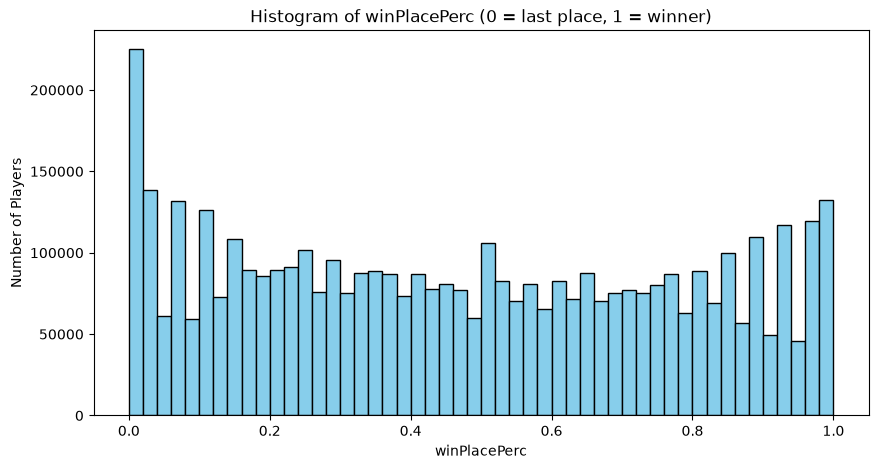

In [19]:
plt.figure(figsize=(10,5))
plt.hist(df['winPlacePerc'], bins=50, color='skyblue', edgecolor='black')
plt.title('Histogram of winPlacePerc (0 = last place, 1 = winner)')
plt.xlabel('winPlacePerc')
plt.ylabel('Number of Players')
plt.show()

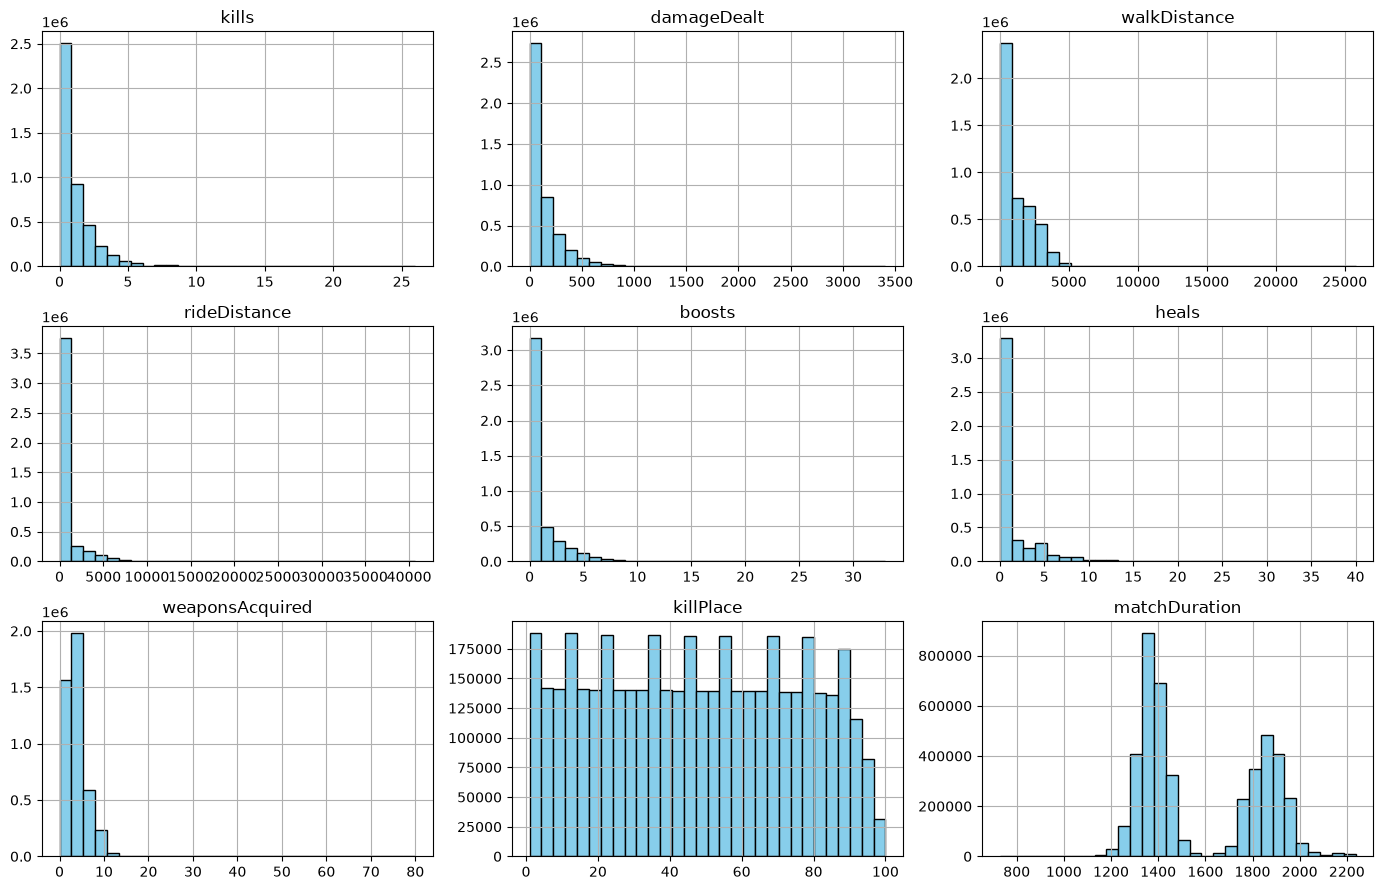

In [20]:
df[['kills', 'damageDealt', 'walkDistance', 'rideDistance', 'boosts', 'heals', 'weaponsAcquired', 'killPlace', 'matchDuration']].hist(
    figsize=(14,9), bins=30, color='skyblue', edgecolor='black')
plt.tight_layout()
plt.show()

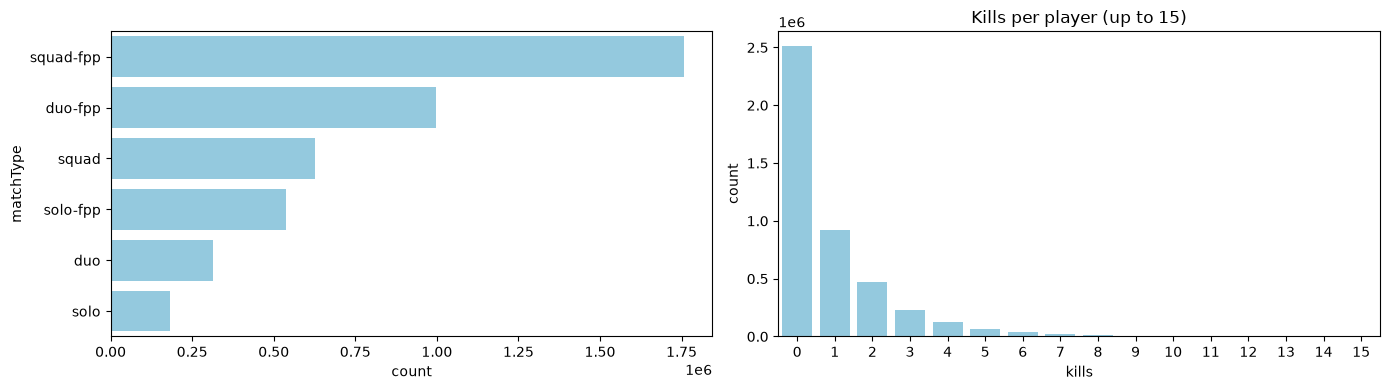

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14,4))
sns.countplot(data=df, y='matchType', order=df['matchType'].value_counts().index, color='skyblue', ax=axes[0])
sns.countplot(data=df[df['kills'] <= 15], x='kills', color='skyblue', ax=axes[1])
axes[1].set_title('Kills per player (up to 15)')
plt.tight_layout()
plt.show()

In [22]:
df[['winPlacePerc', 'kills', 'damageDealt', 'walkDistance', 'rideDistance', 'boosts', 'heals']].skew()

winPlacePerc    0.099559
kills           2.695628
damageDealt     2.507301
walkDistance    1.092126
rideDistance    3.385653
boosts          1.953040
heals           3.356278
dtype: float64

In [23]:
print('players with 0 kills          :', round((df['kills'] == 0).mean() * 100, 1), '%')
print('players who never used a car  :', round((df['rideDistance'] == 0).mean() * 100, 1), '%')
print('players with 0 damage         :', round((df['damageDealt'] == 0).mean() * 100, 1), '%')
print('winners (winPlacePerc = 1)    :', round((df['winPlacePerc'] == 1).mean() * 100, 2), '%')

players with 0 kills          : 57.0 %
players who never used a car  : 74.6 %
players with 0 damage         : 27.9 %
winners (winPlacePerc = 1)    : 2.83 %


**Insights:** `winPlacePerc` is **almost evenly spread from 0 to 1** (skew 0.10, median 0.458), because every match has the same spread of places from first to last. **4.9% of players have 0** (last place) and only **2.83% are winners** (1.0). All the stats are strongly **right-skewed**: **57% of players get no kill**, 27.9% deal no damage at all and **74.6% never use a vehicle**. Kills (skew 2.7), heals (3.4) and ride distance (3.4) are the most skewed: most players do very little, and a few do a lot. **Squad is the most common mode (54% of players)**, then duo (29.7%) and solo (16.3%), and 74.6% of players play in first-person (`fpp`).

## 3. Relational Plots

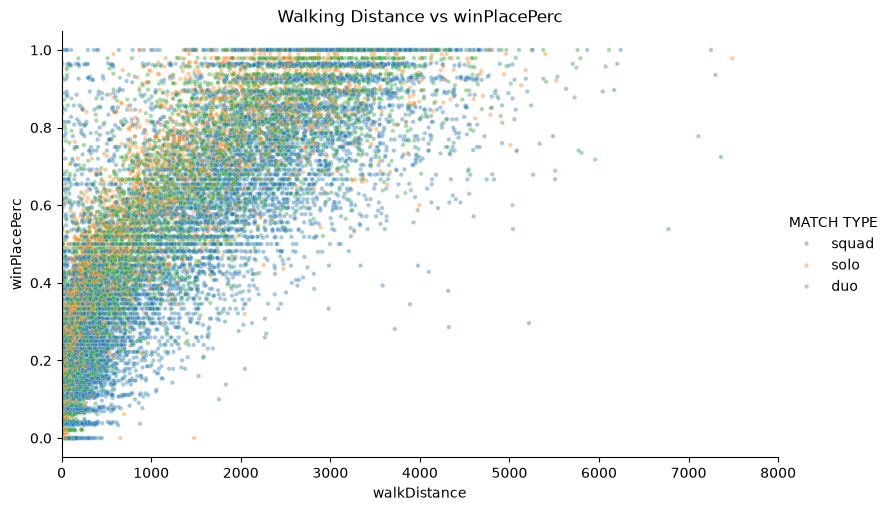

In [24]:
sample = df.sample(20000, random_state=1)
sns.relplot(data=sample, x='walkDistance', y='winPlacePerc', hue='MATCH TYPE', height=5, aspect=1.6, s=10, alpha=0.4)
plt.xlim(0, 8000)
plt.title('Walking Distance vs winPlacePerc')
plt.show()

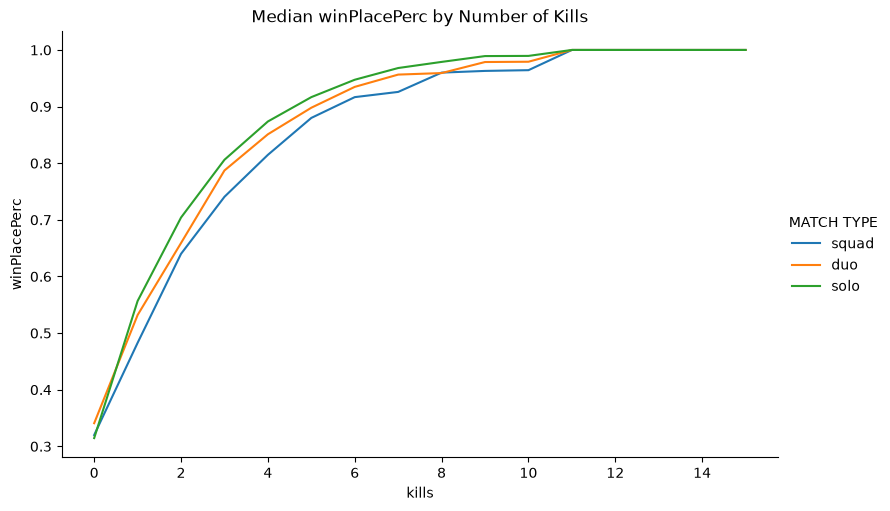

In [25]:
sns.relplot(data=df[df['kills'] <= 15], x='kills', y='winPlacePerc', hue='MATCH TYPE', kind='line', estimator='median', errorbar=None,
            height=5, aspect=1.6)
plt.title('Median winPlacePerc by Number of Kills')
plt.show()

**Insights:** **Walking distance has the strongest relationship with placement.** Players who walked less than a few hundred metres are almost always near the bottom, and players who walked 3 km or more are almost all in the top half. Part of this is the other way round: **players who survive longer have more time to walk**. Placement also rises steadily with **kills**: the median goes from 0.32 with 0 kills to 0.52 with 1 kill, 0.77 with 3 kills and 0.89 with 5 kills, and players with 11 or more kills almost always win. The lines for solo, duo and squad have the same shape, but squad players need fewer kills for the same placement because the kills are shared across 4 team members.

## 4. Pair Plot (Multivariate Analysis)

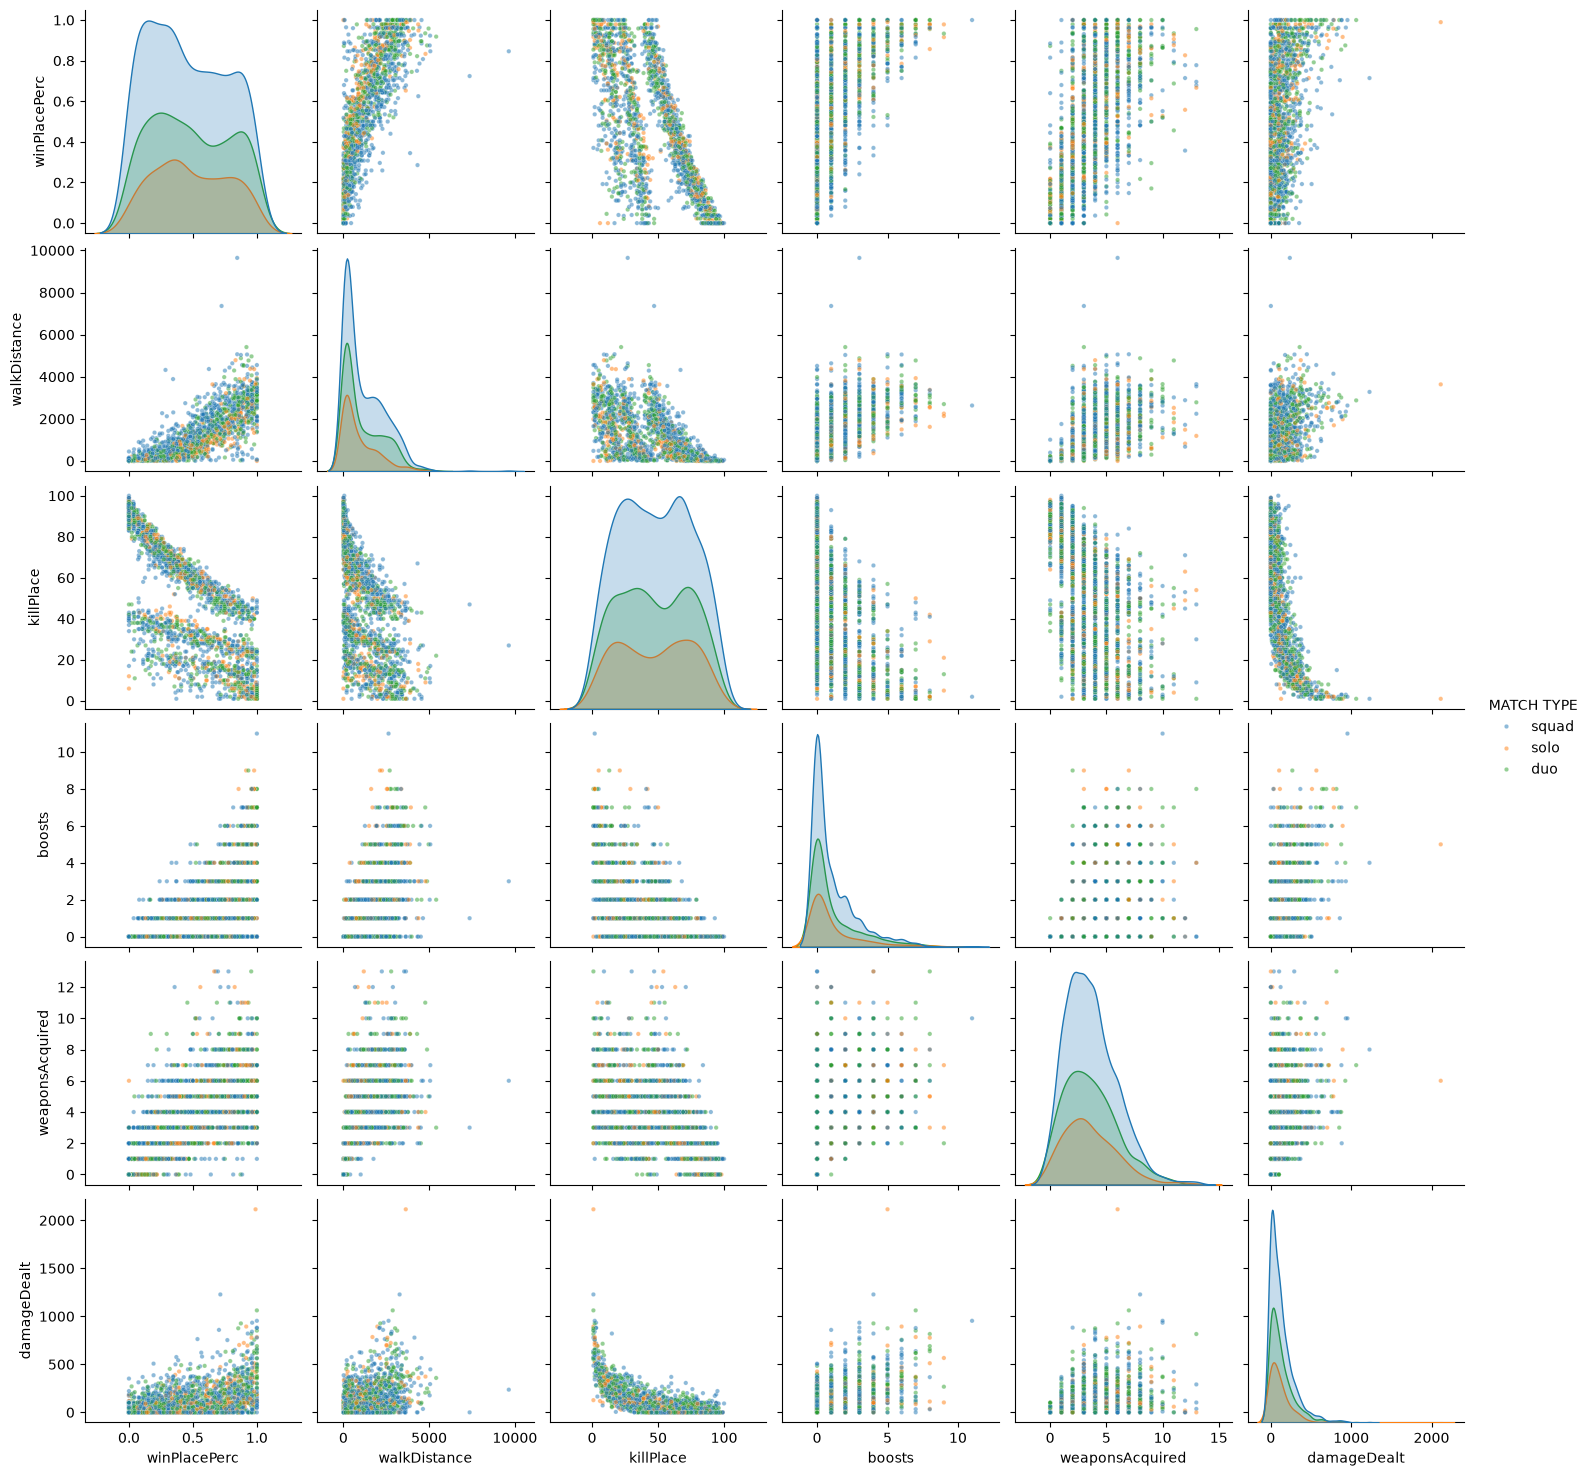

In [26]:
sns.pairplot(df[['winPlacePerc', 'walkDistance', 'killPlace', 'boosts', 'weaponsAcquired', 'damageDealt', 'MATCH TYPE']].sample(2000, random_state=1),
             hue='MATCH TYPE', plot_kws={'s': 10, 'alpha': 0.5})
plt.show()

**Insights:** `walkDistance` and `killPlace` separate the placements most clearly. Players with a **low killPlace** (good rank by kills) and a **long walking distance** are at the top, and players with a high killPlace who barely moved are at the bottom. Boosts and weapons picked up also rise with placement. The three match types overlap almost completely, so the same stats mean about the same thing in solo, duo and squad.

## 5. Data Preprocessing
### Boxplot

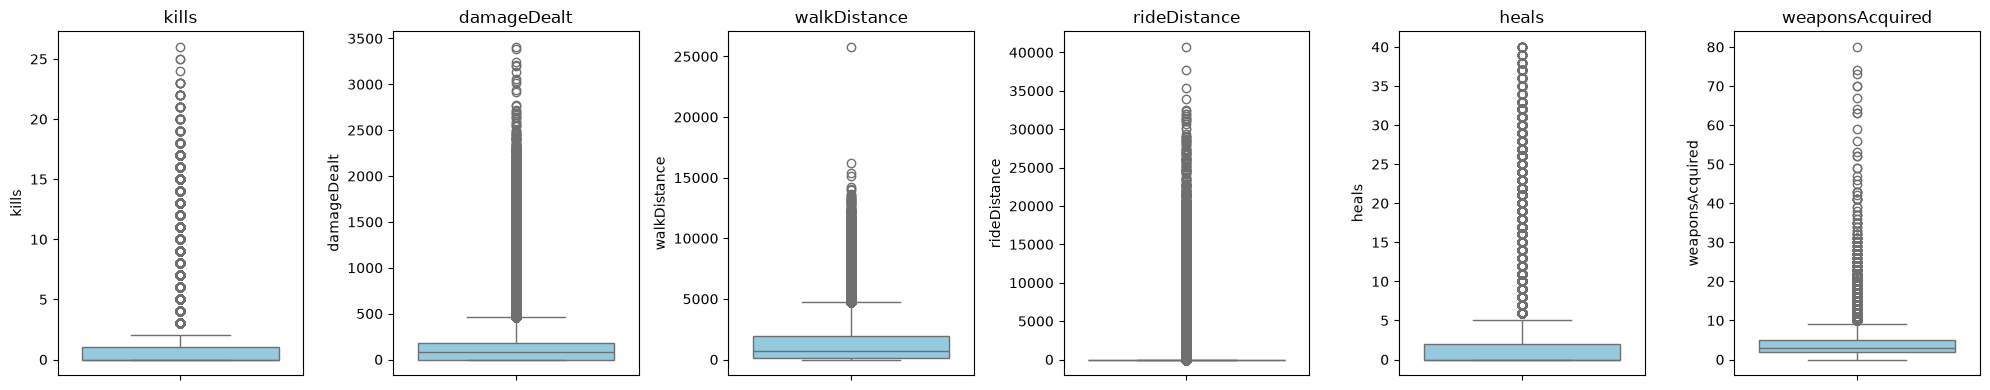

In [27]:
num_cols = ['kills', 'damageDealt', 'walkDistance', 'rideDistance', 'heals', 'weaponsAcquired']
fig, axes = plt.subplots(1, 6, figsize=(20,4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(y=df[col], ax=ax, color='skyblue')
    ax.set_title(col)
plt.tight_layout()
plt.show()

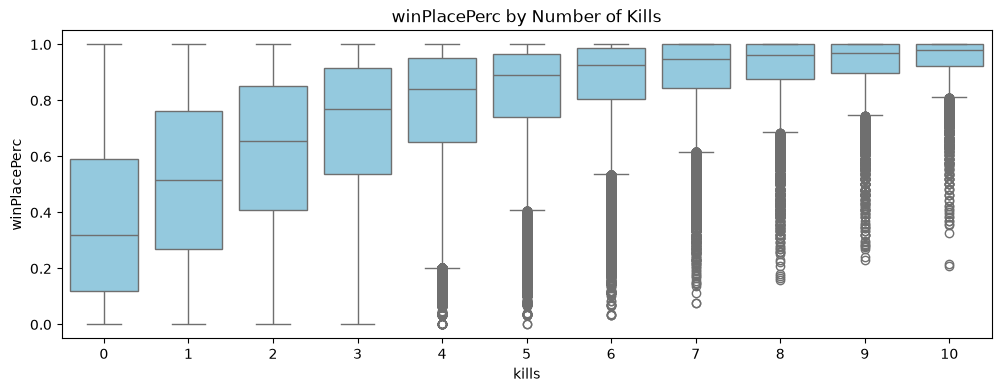

In [28]:
plt.figure(figsize=(12,4))
sns.boxplot(data=df[df['kills'] <= 10], x='kills', y='winPlacePerc', color='skyblue')
plt.title('winPlacePerc by Number of Kills')
plt.show()

In [29]:
# find outliers with the IQR method
for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    print(col, '| upper limit:', round(upper, 1), '| high outliers:', (df[col] > upper).sum(),
          f'({(df[col] > upper).mean() * 100:.1f}%)', '| max:', df[col].max())

kills | upper limit: 2.5 | high outliers: 506760 (11.5%) | max: 26


damageDealt | upper limit: 462.5 | high outliers: 210751 (4.8%) | max: 3407.0


walkDistance | upper limit: 4710.8 | high outliers: 26564 (0.6%) | max: 25780.0
rideDistance | upper limit: 0.0 | high outliers: 1096508 (24.9%) | max: 40710.0


heals | upper limit: 5.0 | high outliers: 320806 (7.3%) | max: 40
weaponsAcquired | upper limit: 9.5 | high outliers: 70855 (1.6%) | max: 80


In [30]:
# are the high-kill players real? look at the top of the list
df.sort_values('kills', ascending=False)[['matchType', 'kills', 'headshotKills', 'damageDealt', 'walkDistance', 'weaponsAcquired', 'winPlacePerc']].head(8)

,matchType,kills,headshotKills,damageDealt,walkDistance,weaponsAcquired,winPlacePerc
1834930,squad-fpp,26,17,2778.0,2360.0,5,1.0000
2381416,squad,25,16,2223.0,4032.0,10,1.0000
1463968,squad-fpp,25,21,2454.0,3068.0,5,1.0000
4390901,squad,24,8,2645.0,3180.0,7,1.0000
3340751,squad,23,13,2127.0,2616.0,4,0.9032
397045,squad-fpp,23,5,2719.0,2423.0,5,1.0000
118093,solo-fpp,23,14,2267.0,3324.0,4,0.9896
4268225,solo-fpp,23,6,2305.0,3467.0,8,1.0000


**Outliers**
- **The IQR method does not fit this data well.** Most players have 0 kills, 0 heals or 0 ride distance, so Q1 and Q3 are very small and almost everything above zero counts as an "outlier": **11.5% of players for kills** (upper limit 2.5) and **24.9% for ride distance** (upper limit 0, so every player who used a car is an outlier).
- **Damage:** 4.8% are above the limit of 462.5 damage (max 3,407). **Walk distance:** 0.6% above 4.7 km (max 25.8 km). **Weapons:** 1.6% above 9.5 (max 80).
- After removing the cheaters, the most extreme players look **real**: the top 8 by kills (23-26 kills) all walked 2-4 km, picked up a normal number of weapons and almost all of them **won the match**. They are just very good players.
- So we **keep all of these values**. They are real, they carry important information (good players really do get many kills), and tree models are not thrown off by extreme values. The only extreme values removed were the clear cheating cases in the cleaning step.

### Line Plot

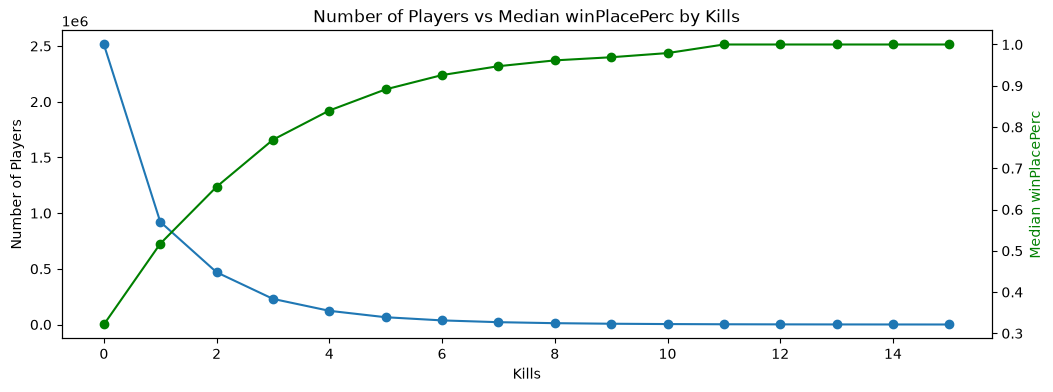

In [31]:
by_kills = df[df['kills'] <= 15].groupby('kills').agg(players=('Id', 'count'), median_place=('winPlacePerc', 'median'))

fig, ax1 = plt.subplots(figsize=(12,4))
ax1.plot(by_kills.index, by_kills['players'], marker='o', label='Number of players')
ax1.set_ylabel('Number of Players')
ax1.set_xlabel('Kills')
ax2 = ax1.twinx()
ax2.plot(by_kills.index, by_kills['median_place'], marker='o', color='green', label='Median winPlacePerc')
ax2.set_ylabel('Median winPlacePerc', color='green')
plt.title('Number of Players vs Median winPlacePerc by Kills')
plt.show()

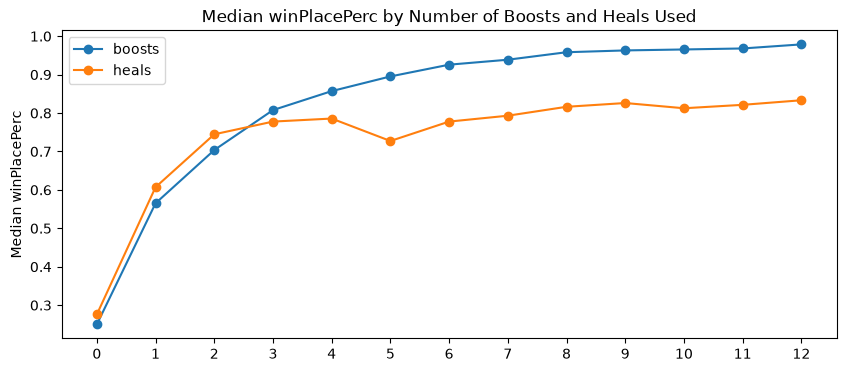

In [32]:
by_boost = df[df['boosts'] <= 12].groupby('boosts')['winPlacePerc'].median()
by_heal = df[df['heals'] <= 12].groupby('heals')['winPlacePerc'].median()
plt.figure(figsize=(10,4))
plt.plot(by_boost.index, by_boost.values, marker='o', label='boosts')
plt.plot(by_heal.index, by_heal.values, marker='o', label='heals')
plt.title('Median winPlacePerc by Number of Boosts and Heals Used')
plt.ylabel('Median winPlacePerc')
plt.xticks(range(0, 13))
plt.legend()
plt.show()

**Insights:**
- The number of players falls quickly as kills go up (**2.5 million players with 0 kills**, 0.9 million with 1, only 37,000 with 6), while the median placement rises: **each extra kill moves a player up**, but the gain gets smaller after about 5 kills (0.89) because those players are already near the top.
- **Boosts** (energy drinks, painkillers) have a strong, steady effect: the median placement goes from **0.25 with 0 boosts** to 0.57 with 1, 0.81 with 3 and **0.93 with 6**.
- **Heals** rise quickly up to 2-3 heals (0.75-0.78) and then **level off** at about 0.78-0.83. Using more heals beyond that does not go with a better placement; it usually means the player is taking a lot of damage.

### Barplot

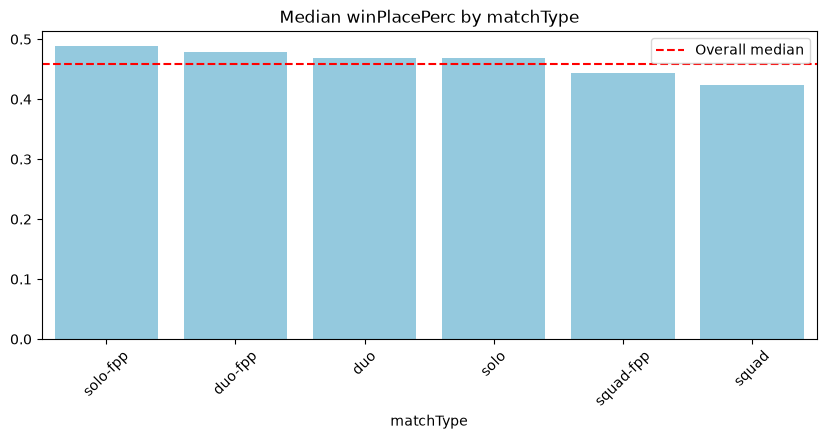

In [33]:
df['WALK GROUP'] = pd.cut(df['walkDistance'], bins=[-1, 100, 500, 1000, 2000, 3000, 5000, 30000],
                          labels=['0-100m', '100-500m', '500m-1km', '1-2km', '2-3km', '3-5km', '5km+'])
df['WEAPONS GROUP'] = pd.cut(df['weaponsAcquired'], bins=[-1, 0, 2, 4, 6, 8, 300], labels=['0', '1-2', '3-4', '5-6', '7-8', '9+'])
df['USED VEHICLE'] = np.where(df['rideDistance'] > 0, 'yes', 'no')

def place_plot(col, order=None):
    place = df.groupby(col)['winPlacePerc'].median()
    place = place.reindex(order) if order else place.sort_values(ascending=False)
    plt.figure(figsize=(10,4))
    sns.barplot(x=place.index.astype(str), y=place.values, color='skyblue')
    plt.axhline(df['winPlacePerc'].median(), color='red', linestyle='--', label='Overall median')
    plt.title('Median winPlacePerc by ' + col)
    plt.xticks(rotation=45)
    plt.legend()
    plt.show()

place_plot('matchType')

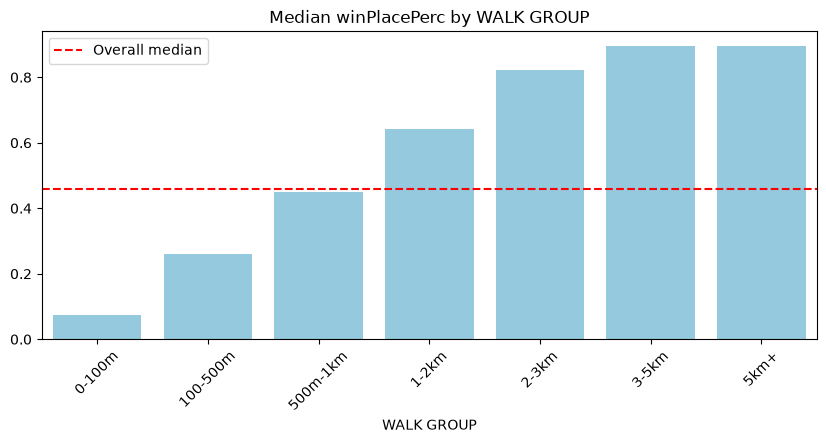

In [34]:
place_plot('WALK GROUP', ['0-100m', '100-500m', '500m-1km', '1-2km', '2-3km', '3-5km', '5km+'])

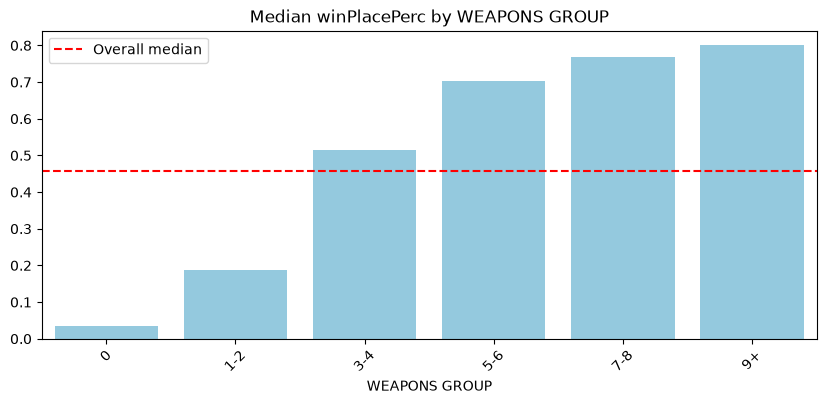

In [35]:
place_plot('WEAPONS GROUP', ['0', '1-2', '3-4', '5-6', '7-8', '9+'])

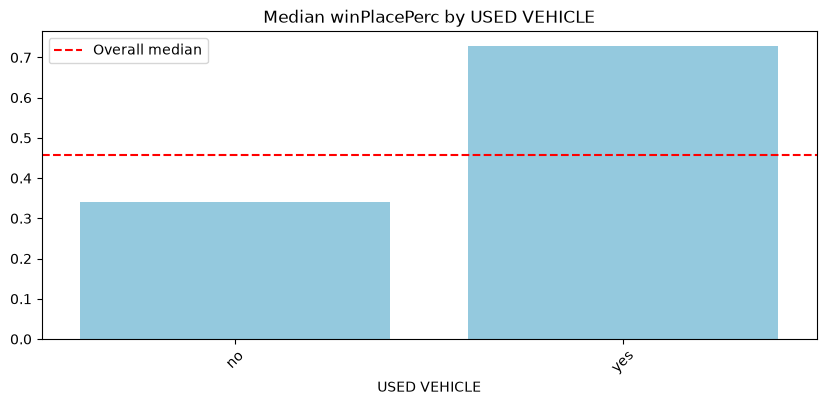

In [36]:
place_plot('USED VEHICLE', ['no', 'yes'])

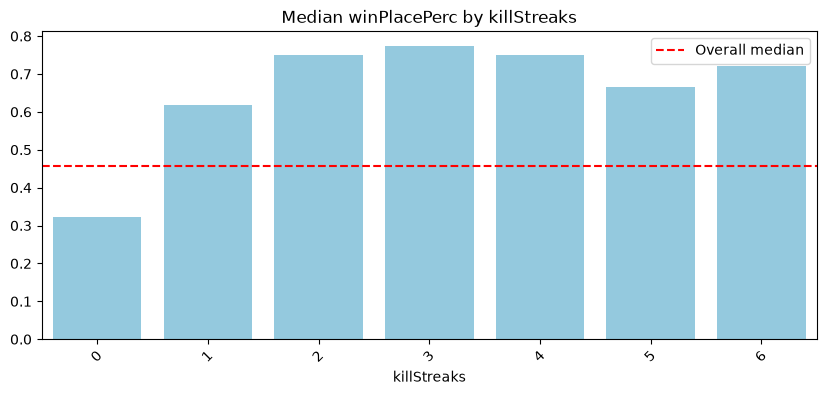

In [37]:
place_plot('killStreaks', list(range(0, 7)))

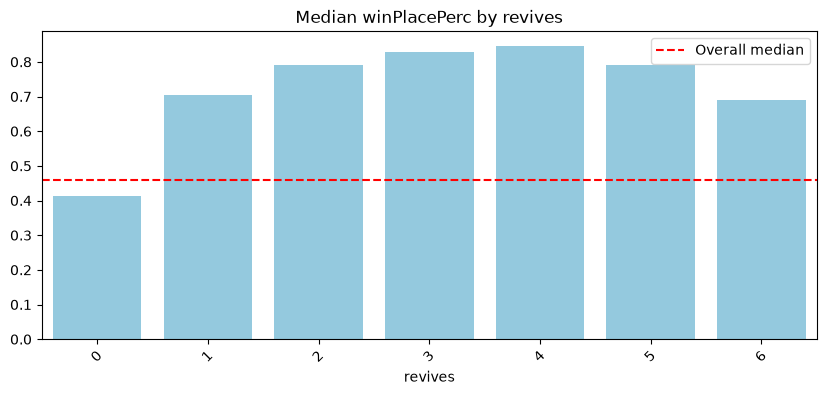

In [38]:
place_plot('revives', list(range(0, 7)))

**Insights** (red line = overall median placement of 0.458)
- **Match type:** the medians are close (0.42 to 0.49). Squad (tpp) is lowest at 0.423 and solo-fpp highest at 0.489. These differences come from how the places are counted (fewer teams in squad), not from one mode being easier.
- **Walking distance:** the clearest pattern. Players who walked **under 100 m have a median of only 0.074**, 500 m-1 km 0.449, 1-2 km 0.643, 2-3 km 0.821 and **3 km or more about 0.90**.
- **Weapons picked up:** 0 weapons gives 0.034, 3-4 weapons 0.516, 5-6 weapons 0.704 and 9 or more 0.80. The gain gets much smaller after about 5 weapons.
- **Vehicle:** players who used a vehicle have a **median of 0.729 vs 0.340** for those who did not.
- **Kill streaks:** the median rises to about 0.77 at 3 kills in a row and then stops rising (fewer players, more random).
- **Revives** (duo / squad): reviving one teammate goes with a big jump (**0.414 to 0.704**), and 3-4 revives with about 0.83-0.85.

*Note: some of these groups mix very different players (for example, players who survive longer have more time to walk, drive and pick up weapons). We check this in Part 3 by comparing players within the same match type and the same walking distance.*

### Encoding
Machine learning models need numbers, so we convert the text column `matchType` into numbers with `LabelEncoder`. `Id` is dropped. `groupId` and `matchId` are not features, but they are kept aside because they are needed later to split the data by match and to average predictions per team.

In [39]:
from sklearn.preprocessing import LabelEncoder

data = df.drop(columns=['Id', 'MATCH TYPE', 'WALK GROUP', 'WEAPONS GROUP', 'USED VEHICLE']).copy()
le = LabelEncoder()
data['matchType'] = le.fit_transform(data['matchType'])
data.head()

,groupId,matchId,assists,boosts,damageDealt,DBNOs,headshotKills,heals,killPlace,killPoints,kills,killStreaks,longestKill,matchDuration,matchType,maxPlace,numGroups,rankPoints,revives,rideDistance,roadKills,swimDistance,teamKills,vehicleDestroys,walkDistance,weaponsAcquired,winPoints,winPlacePerc,PLAYERS IN MATCH,TEAM SIZE,TOTAL DISTANCE,HEALS AND BOOSTS,HEADSHOT RATE,KILLPLACE PERC,WALK RANK
0,4d4b580de459be,a10357fd1a4a91,0,0,0.00,0,0,0,60,1241,0,0,0.00,1306,5,28,26,-1,0,0.0000,0,0.00,0,0,244.80,1,1466,0.4444,96,4,244.8000,0,0.0,0.625000,0.479167
1,684d5656442f9e,aeb375fc57110c,0,0,91.47,0,0,0,57,0,0,0,0.00,1777,5,26,25,1484,0,0.0045,0,11.04,0,0,1434.00,5,0,0.6400,91,4,1445.0445,0,0.0,0.626374,0.560440
2,6a4a42c3245a74,110163d8bb94ae,1,0,68.00,0,0,0,47,0,0,0,0.00,1318,0,50,47,1491,0,0.0000,0,0.00,0,0,161.80,2,0,0.7755,98,2,161.8000,0,0.0,0.479592,0.377551
3,a930a9c79cd721,f1f1f4ef412d7e,0,0,32.90,0,0,0,75,0,0,0,0.00,1436,5,31,30,1408,0,0.0000,0,0.00,0,0,202.70,3,0,0.1667,91,1,202.7000,0,0.0,0.824176,0.230769
4,de04010b3458dd,6dc8ff871e21e6,0,0,100.00,0,0,0,45,0,1,1,58.53,1424,3,97,95,1560,0,0.0000,0,0.00,0,0,49.75,2,0,0.1875,97,1,49.7500,0,0.0,0.463918,0.206186


## 6. Feature Selection & Heat Map

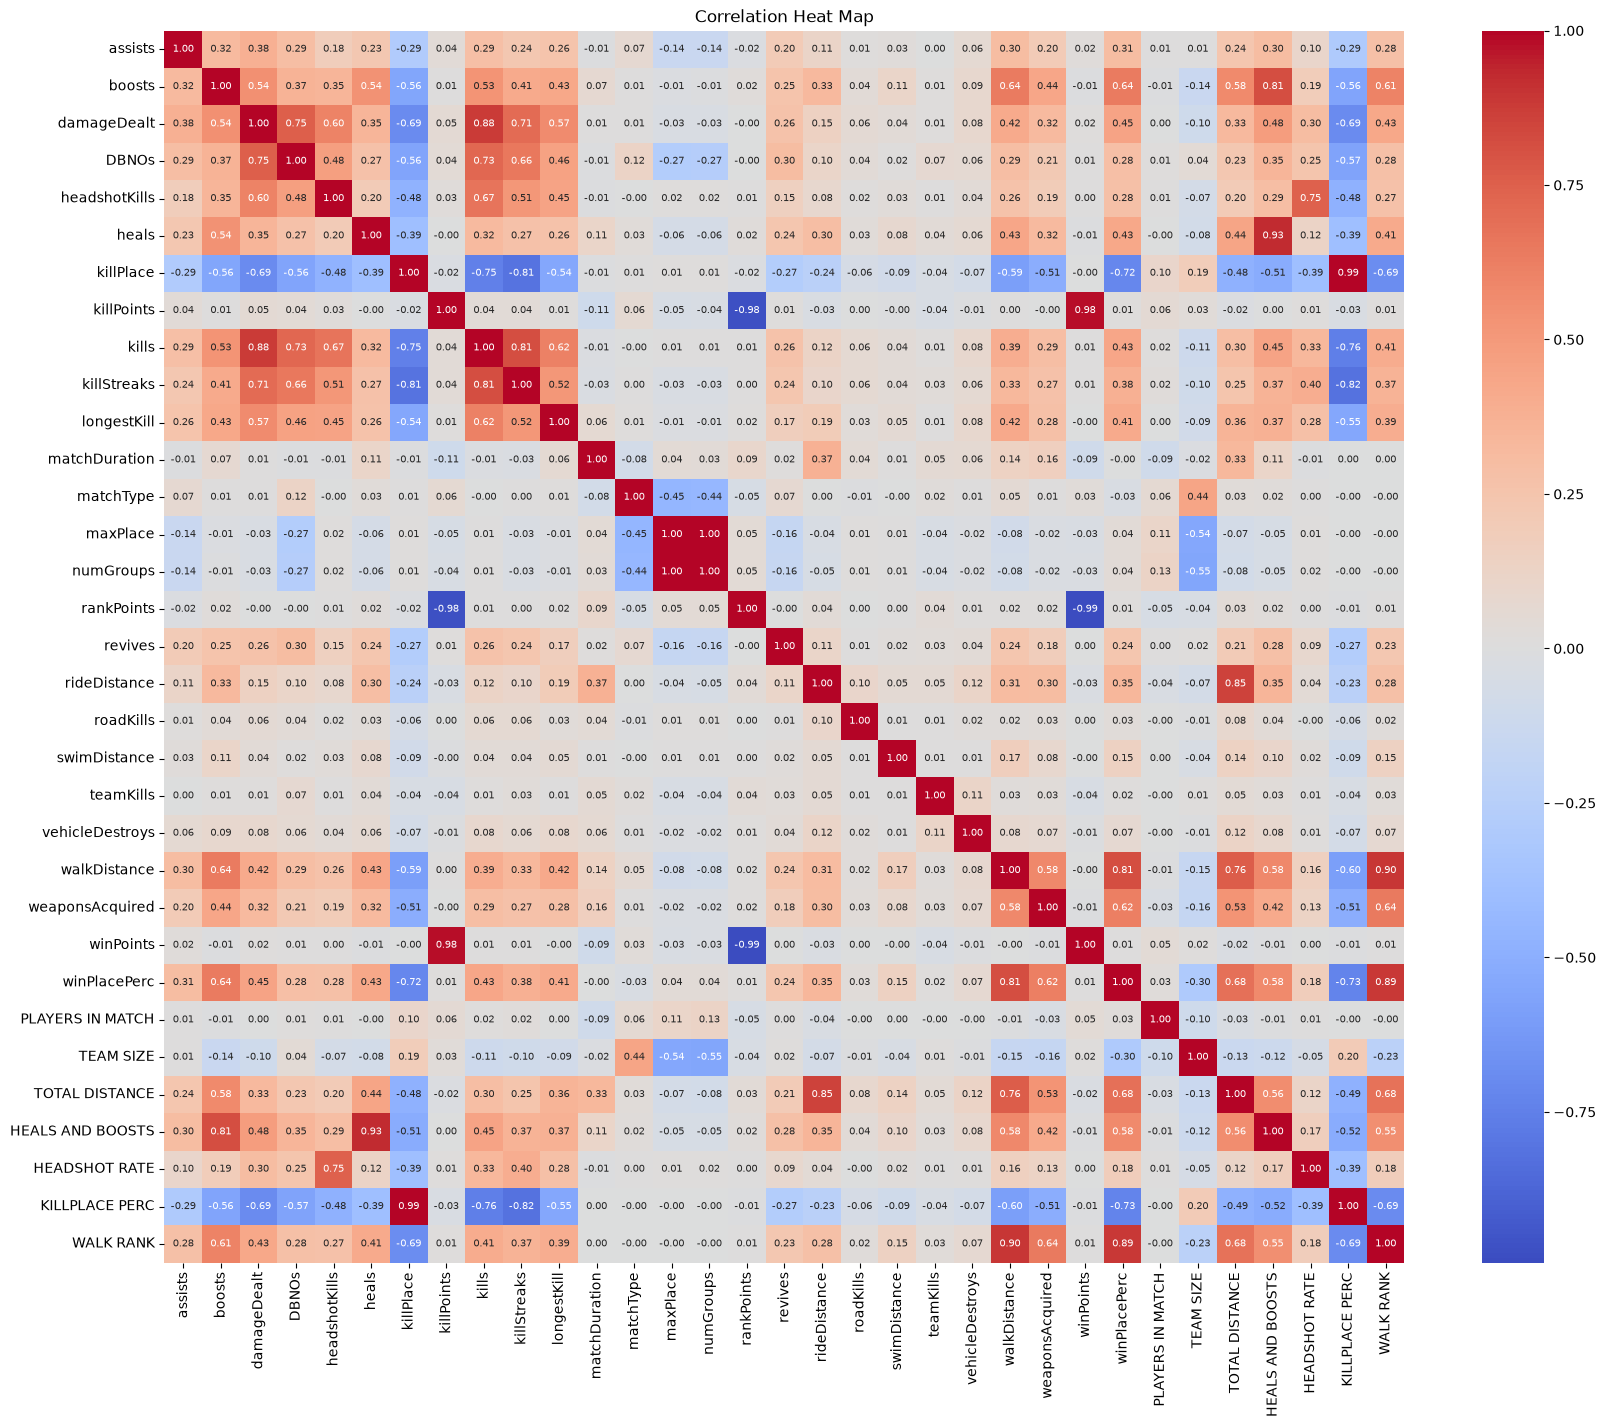

In [40]:
plt.figure(figsize=(20,16))
sns.heatmap(data.drop(columns=['matchId', 'groupId']).corr(), annot=True, fmt='.2f', cmap='coolwarm', annot_kws={'size': 7})
plt.title('Correlation Heat Map')
plt.show()

In [41]:
data.drop(columns=['matchId', 'groupId']).corr()['winPlacePerc'].sort_values(ascending=False)

winPlacePerc        1.000000
WALK RANK           0.890452
walkDistance        0.814671
TOTAL DISTANCE      0.681957
boosts              0.636463
weaponsAcquired     0.620524
HEALS AND BOOSTS    0.579251
damageDealt         0.450699
kills               0.431654
heals               0.431200
longestKill         0.412477
killStreaks         0.378099
rideDistance        0.345394
assists             0.305670
DBNOs               0.284176
headshotKills       0.282701
revives             0.241888
HEADSHOT RATE       0.181201
swimDistance        0.150899
vehicleDestroys     0.072854
numGroups           0.040817
maxPlace            0.038540
roadKills           0.032321
PLAYERS IN MATCH    0.026198
teamKills           0.016403
rankPoints          0.013756
killPoints          0.013003
winPoints           0.006996
matchDuration      -0.004247
matchType          -0.031295
TEAM SIZE          -0.297280
killPlace          -0.720962
KILLPLACE PERC     -0.729002
Name: winPlacePerc, dtype: float64

In [42]:
# pairs of columns that carry almost the same information
data[['maxPlace', 'numGroups', 'PLAYERS IN MATCH']].corr().round(3)

,maxPlace,numGroups,PLAYERS IN MATCH
maxPlace,1.000,0.998,0.107
numGroups,0.998,1.000,0.126
PLAYERS IN MATCH,0.107,0.126,1.000


In [43]:
data[['kills', 'damageDealt', 'DBNOs', 'killStreaks', 'killPlace', 'KILLPLACE PERC']].corr().round(2)

,kills,damageDealt,DBNOs,killStreaks,killPlace,KILLPLACE PERC
kills,1.00,0.88,0.73,0.81,-0.75,-0.76
damageDealt,0.88,1.00,0.75,0.71,-0.69,-0.69
DBNOs,0.73,0.75,1.00,0.66,-0.56,-0.57
killStreaks,0.81,0.71,0.66,1.00,-0.81,-0.82
killPlace,-0.75,-0.69,-0.56,-0.81,1.00,0.99
KILLPLACE PERC,-0.76,-0.69,-0.57,-0.82,0.99,1.00


**Feature selection**
- **`WALK RANK` (0.89)** has the strongest correlation with placement, even more than `walkDistance` (0.81), because it compares the player with the other players **in the same match** (long matches have more walking for everyone).
- **`killPlace` (-0.72) and `KILLPLACE PERC` (-0.73)** are strongly negative: a smaller killPlace (better rank) means a higher placement. They are almost the same (0.99), but both are kept: `KILLPLACE PERC` adjusts for the number of players in the match.
- Boosts (0.64), weapons picked up (0.62), damage (0.45), kills (0.43) and heals (0.43) are also strong. `kills` and `damageDealt` are related (0.88) but not the same, so both are kept for the tree models.
- **`maxPlace` is dropped**, because it is almost exactly the same as `numGroups` (0.998).
- **`killPoints`, `winPoints` and `rankPoints` are dropped**: they have almost no correlation with placement (0.01) and are filled with -1 or 0 ("no value") in 38-60% of rows.
- `Id`, `groupId` and `matchId` are IDs, not features. `groupId` and `matchId` are kept aside for splitting the data and for averaging per team.
- The features kept are the remaining **28 columns**: all the in-game stats, `matchType`, `matchDuration`, `numGroups`, and the new columns `PLAYERS IN MATCH`, `TEAM SIZE`, `TOTAL DISTANCE`, `HEALS AND BOOSTS`, `HEADSHOT RATE`, `KILLPLACE PERC` and `WALK RANK`.

# Part 2: Predictive Model

## Which algorithm suits this data best?
We want to predict **winPlacePerc**, a number between 0 (last place) and 1 (winner), so this is a **supervised regression** problem.
- Logistic Regression and Naive Bayes are for classification (yes / no answers), so they don't fit.
- K-Means and PCA are unsupervised, so they don't fit.
- SVM (SVR) is far too slow for this many rows.
- Linear Regression, Decision Tree, KNN, Random Forest and Gradient Boosting can all predict numbers, so we try all five and compare them.

We judge the models on **R²** (how much of the variation in placement the model explains, 1.0 is perfect), **MAE** (the average error, e.g. 0.06 = about 6 places out of 100), **RMSE** (like MAE but punishes big mistakes more) and the share of players predicted **within 0.1** of their real placement.

**Expected Best: Random Forest or Gradient Boosting**, because placement depends on combinations of features (e.g. walking a lot matters more in a long match) and tree models handle this well.

### Using a sample of matches
The full data has about 4.4 million rows. Training 5 models, cross-validation and hyperparameter searches on all of it would take many hours, so we train on a **random sample of 600 whole matches** (about 55,000 players). We take **whole matches**, not random rows, because the features like `killPlace` and `WALK RANK` only make sense inside a complete match.

### Splitting by match (not by row)
All players in the same team get **the same winPlacePerc**. If one teammate is in the training set and another in the test set, the model can "remember" the team and the score looks better than it really is. So the train / test split and all cross-validation folds are made **by match** (`GroupShuffleSplit` and `GroupKFold`): every match is either completely in training or completely in testing.

In [44]:
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler

matches = data['matchId'].drop_duplicates().sample(600, random_state=42)
model_data = data[data['matchId'].isin(matches)].reset_index(drop=True)

X = model_data.drop(columns=['winPlacePerc', 'matchId', 'groupId', 'killPoints', 'winPoints', 'rankPoints', 'maxPlace'])
y = model_data['winPlacePerc']
match_ids = model_data['matchId']

split = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(split.split(X, y, groups=match_ids))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
groups_train = match_ids.iloc[train_idx]

# scale the features (needed for Linear Regression and KNN, does not change tree models)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

print('Sample:', model_data.shape, '| matches:', model_data['matchId'].nunique())
print(X_train.shape, X_test.shape)
print('Mean winPlacePerc in train:', round(y_train.mean(), 3), '| in test:', round(y_test.mean(), 3))
print('Matches in both train and test:', len(set(groups_train) & set(match_ids.iloc[test_idx])))

Sample: (56168, 35) | matches: 600
(44883, 28) (11285, 28)
Mean winPlacePerc in train: 0.474 | in test: 0.474
Matches in both train and test: 0


In [45]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

def within(y_true, pred, gap=0.1):
    return (np.abs(np.asarray(y_true) - pred) <= gap).mean() * 100

models = {
    'Linear Regression': LinearRegression(),
    'Decision Tree': DecisionTreeRegressor(max_depth=12, min_samples_leaf=5, random_state=42),
    'KNN': KNeighborsRegressor(n_neighbors=10),
    'Random Forest': RandomForestRegressor(n_estimators=200, min_samples_leaf=3, random_state=42, n_jobs=-1),
    'Gradient Boosting': GradientBoostingRegressor(random_state=42),
}

results = []
for name, model in models.items():
    model.fit(X_train_s, y_train)
    y_pred = model.predict(X_test_s)
    results.append([name, r2_score(y_train, model.predict(X_train_s)), r2_score(y_test, y_pred),
                    mean_absolute_error(y_test, y_pred), np.sqrt(mean_squared_error(y_test, y_pred)), within(y_test, y_pred)])

results = pd.DataFrame(results, columns=['Model', 'Train R2', 'Test R2', 'MAE', 'RMSE', '% within 0.1'])
results.sort_values('Test R2', ascending=False).round(4)

,Model,Train R2,Test R2,MAE,RMSE,% within 0.1
3,Random Forest,0.9827,0.9311,0.0580,0.0806,82.4369
4,Gradient Boosting,0.9238,0.9205,0.0622,0.0866,80.2658
1,Decision Tree,0.9460,0.9090,0.0657,0.0926,77.8821
2,KNN,0.9114,0.8930,0.0731,0.1004,73.7794
0,Linear Regression,0.8693,0.8672,0.0812,0.1119,70.6159


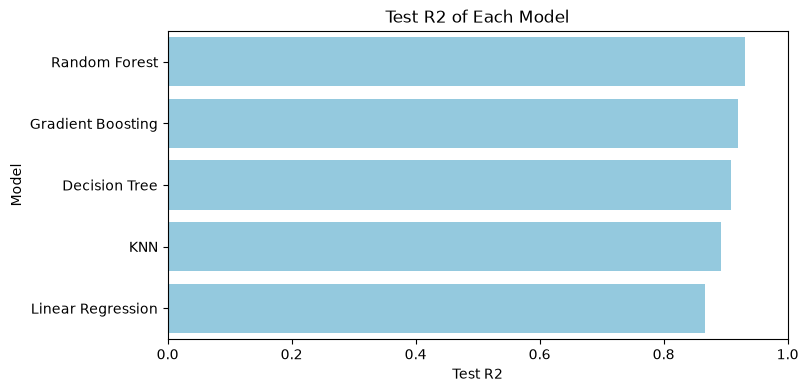

In [46]:
plt.figure(figsize=(8,4))
sns.barplot(data=results.sort_values('Test R2', ascending=False), x='Test R2', y='Model', color='skyblue')
plt.title('Test R2 of Each Model')
plt.xlim(0, 1)
plt.show()

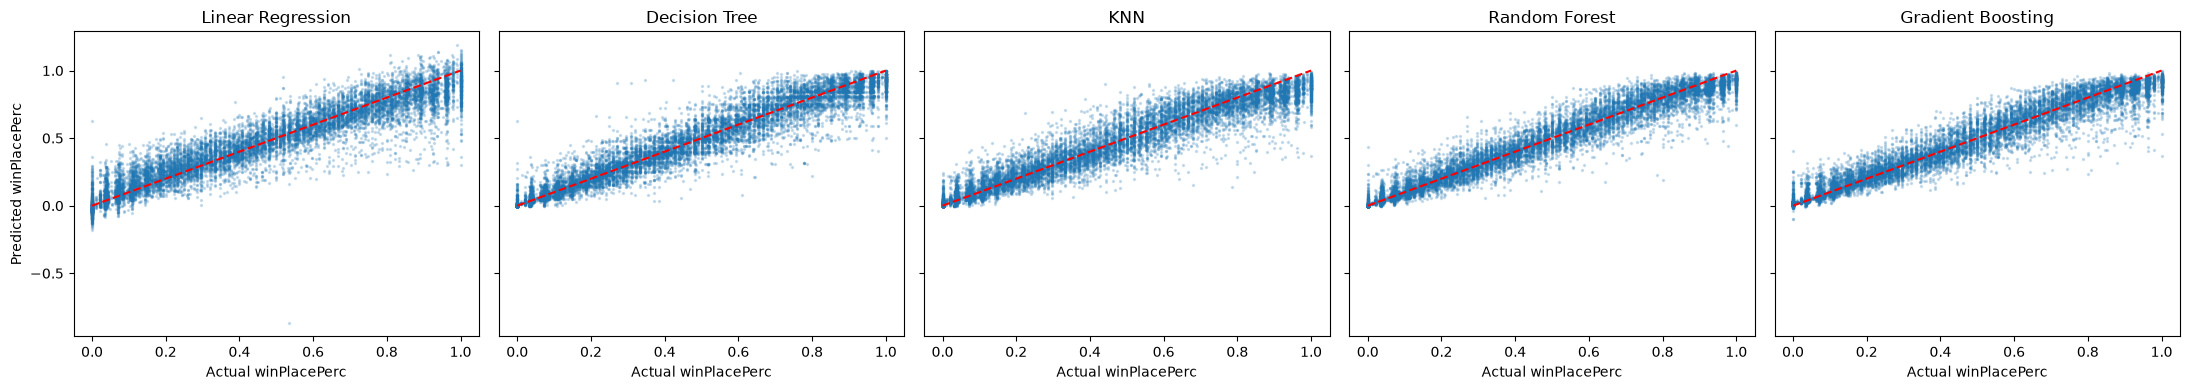

In [47]:
fig, axes = plt.subplots(1, 5, figsize=(22,4), sharex=True, sharey=True)
for ax, (name, model) in zip(axes, models.items()):
    ax.scatter(y_test, model.predict(X_test_s), s=2, alpha=0.2)
    ax.plot([0, 1], [0, 1], color='red', linestyle='--')
    ax.set_title(name)
    ax.set_xlabel('Actual winPlacePerc')
axes[0].set_ylabel('Predicted winPlacePerc')
plt.tight_layout()
plt.show()

### Cross-validation check
One test split can favour a model by luck, so we check the models with **5-fold cross-validation** (`GroupKFold`, so a match is never split between training and testing). We also try a **tuned Gradient Boosting** (more and deeper trees).

In [48]:
from sklearn.model_selection import GroupKFold, cross_validate, cross_val_score
from sklearn.pipeline import make_pipeline

cv_models = {
    'Linear Regression': make_pipeline(StandardScaler(), LinearRegression()),
    'Decision Tree': DecisionTreeRegressor(max_depth=12, min_samples_leaf=5, random_state=42),
    'KNN': make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=10)),
    'Random Forest': RandomForestRegressor(n_estimators=200, min_samples_leaf=3, random_state=42, n_jobs=-1),
    'Gradient Boosting': GradientBoostingRegressor(random_state=42),
    'Gradient Boosting (tuned)': GradientBoostingRegressor(n_estimators=400, learning_rate=0.1, max_depth=6,
                                                           subsample=0.8, random_state=42),
}

cv = GroupKFold(n_splits=5)
cv_results = []
for name, model in cv_models.items():
    scores = cross_validate(model, X, y, groups=match_ids, cv=cv, scoring=['r2', 'neg_mean_absolute_error'], n_jobs=5)
    cv_results.append([name, scores['test_r2'].mean(), scores['test_r2'].std(), -scores['test_neg_mean_absolute_error'].mean()])

cv_results = pd.DataFrame(cv_results, columns=['Model', 'CV R2 (mean)', 'CV R2 (std)', 'CV MAE'])
cv_results.sort_values('CV R2 (mean)', ascending=False).round(4)

,Model,CV R2 (mean),CV R2 (std),CV MAE
5,Gradient Boosting (tuned),0.9358,0.0021,0.0559
3,Random Forest,0.9323,0.0023,0.0566
4,Gradient Boosting,0.9209,0.0021,0.0610
1,Decision Tree,0.9096,0.0020,0.0647
2,KNN,0.8893,0.0031,0.0734
0,Linear Regression,0.8686,0.0046,0.0805


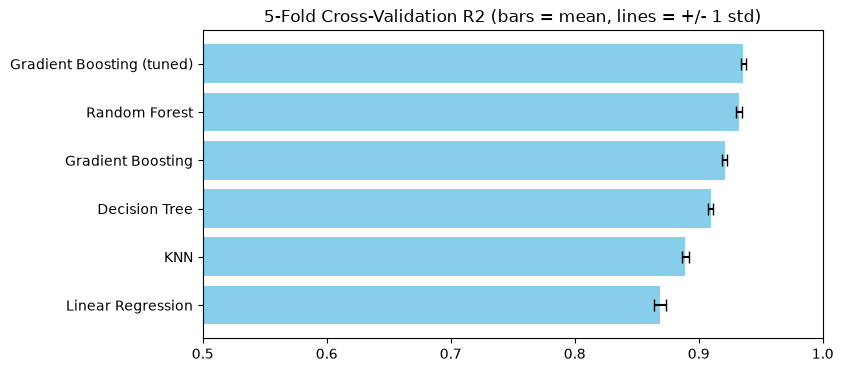

In [49]:
cv_sorted = cv_results.sort_values('CV R2 (mean)')
plt.figure(figsize=(8,4))
plt.barh(cv_sorted['Model'], cv_sorted['CV R2 (mean)'], xerr=cv_sorted['CV R2 (std)'], color='skyblue', capsize=4)
plt.title('5-Fold Cross-Validation R2 (bars = mean, lines = +/- 1 std)')
plt.xlim(0.5, 1)
plt.show()

**Cross-validation result:** the **tuned Gradient Boosting (0.936)** is the best, just ahead of Random Forest (0.932). The gap (0.0035) is small but bigger than the variation between folds (std about 0.002), so it is a real difference. The default Gradient Boosting (0.921) was clearly worse than the tuned one, because 100 shallow trees are too simple. The order is the same as on the single test split: Random Forest and Gradient Boosting first, then Decision Tree (0.910), KNN (0.889) and Linear Regression (0.869).

**Linear Regression does surprisingly well here (0.87)**, much better than in many datasets, because the strongest features (`WALK RANK`, `killPlace`) have an almost straight-line relationship with placement. Because we split **by match**, the cross-validated scores are almost identical to the test-split scores (e.g. Random Forest 0.932 vs 0.931), and the std is very small, so these results are reliable.

## Hyperparameter Tuning
So far the models used hand-picked settings. Here we search for better settings in a structured way:
1. **GridSearchCV** on Random Forest: try every combination of `n_estimators` and `max_depth`.
2. **RandomizedSearchCV** on Random Forest: try 20 random combinations from a wider range of settings.
3. **RandomizedSearchCV** on **HistGradientBoosting**, a faster version of Gradient Boosting. Boosting builds trees one after another, each fixing the mistakes of the previous ones, unlike Random Forest which builds independent trees and averages them.

All searches use **only the training data** with 3-fold `GroupKFold` and are scored on R². The test set is kept aside for the final comparison.

*Note: this section takes a long time to run (the whole notebook takes about 2 hours).*

In [50]:
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.ensemble import HistGradientBoostingRegressor
from scipy.stats import randint, loguniform

cv3 = GroupKFold(n_splits=3)

# 1. Grid search: n_estimators x max_depth
rf_grid = GridSearchCV(RandomForestRegressor(min_samples_leaf=3, random_state=42, n_jobs=-1),
                       param_grid={'n_estimators': [100, 200, 300], 'max_depth': [6, 10, 15, 20, 30, None]},
                       scoring='r2', cv=cv3)
rf_grid.fit(X_train, y_train, groups=groups_train)
print('Best settings :', rf_grid.best_params_)
print('Best CV R2    :', round(rf_grid.best_score_, 4))

Best settings : {'max_depth': 30, 'n_estimators': 300}
Best CV R2    : 0.9306


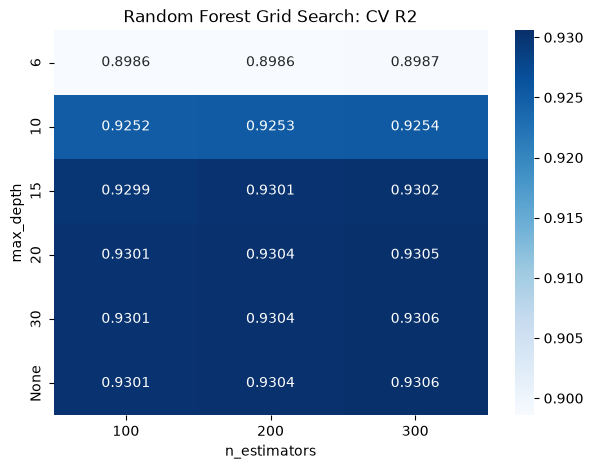

In [51]:
grid_table = pd.DataFrame(rf_grid.cv_results_)
grid_table['max_depth'] = grid_table['param_max_depth'].apply(lambda d: 'None' if pd.isna(d) else str(int(d)))   # so that None is shown too
grid_table = grid_table.pivot_table(index='max_depth', columns='param_n_estimators', values='mean_test_score')
grid_table = grid_table.reindex(['6', '10', '15', '20', '30', 'None'])

plt.figure(figsize=(7,5))
sns.heatmap(grid_table, annot=True, fmt='.4f', cmap='Blues')
plt.title('Random Forest Grid Search: CV R2')
plt.xlabel('n_estimators')
plt.show()

In [52]:
# 2. Randomized search on Random Forest (wider range of settings)
rf_random = RandomizedSearchCV(RandomForestRegressor(random_state=42, n_jobs=-1),
                               param_distributions={'n_estimators': randint(100, 400),
                                                    'max_depth': [10, 15, 20, 30, None],
                                                    'min_samples_leaf': randint(1, 10),
                                                    'max_features': ['sqrt', 'log2', 0.5, 0.7, 1.0]},
                               n_iter=20, scoring='r2', cv=cv3, random_state=42)
rf_random.fit(X_train, y_train, groups=groups_train)
print('Best settings :', rf_random.best_params_)
print('Best CV R2    :', round(rf_random.best_score_, 4))

Best settings : {'max_depth': 15, 'max_features': 0.7, 'min_samples_leaf': 3, 'n_estimators': 154}
Best CV R2    : 0.9308


In [53]:
# 3. Randomized search on HistGradientBoosting
hgb_random = RandomizedSearchCV(HistGradientBoostingRegressor(random_state=42, early_stopping=False),
                                param_distributions={'learning_rate': loguniform(0.01, 0.3),
                                                     'max_iter': randint(200, 1000),
                                                     'max_depth': [4, 6, 8, 10, None],
                                                     'max_leaf_nodes': randint(15, 127),
                                                     'min_samples_leaf': randint(2, 50),
                                                     'l2_regularization': loguniform(0.001, 10)},
                                n_iter=30, scoring='r2', cv=cv3, random_state=42)
hgb_random.fit(X_train, y_train, groups=groups_train)
print('Best settings :', hgb_random.best_params_)
print('Best CV R2    :', round(hgb_random.best_score_, 4))

Best settings : {'l2_regularization': np.float64(0.5884968350790237), 'learning_rate': np.float64(0.025000844824995944), 'max_depth': 8, 'max_iter': 573, 'max_leaf_nodes': 46, 'min_samples_leaf': 33}
Best CV R2    : 0.9377


## Ensembles Beyond Bagging
Random Forest is a **bagging** ensemble (many trees on random samples, averaged). We also try two ways of combining *different kinds* of models:
- **Voting:** average the predictions of the tuned Random Forest, the tuned HistGradientBoosting and the tuned Gradient Boosting.
- **Stacking:** the base models (tuned Random Forest, tuned HistGradientBoosting, Extra Trees and KNN) make predictions, and a Ridge regression **meta-model** learns how much to trust each one.

The stacking folds are also made **by match** (`GroupKFold`), so the meta-model never learns from a teammate's prediction.

In [54]:
from sklearn.ensemble import VotingRegressor, StackingRegressor, ExtraTreesRegressor
from sklearn.linear_model import Ridge

voting = VotingRegressor([('rf', rf_random.best_estimator_), ('hgb', hgb_random.best_estimator_),
                          ('gb', cv_models['Gradient Boosting (tuned)'])])
voting.fit(X_train, y_train)

# StackingRegressor cannot pass groups to its folds, so we give it the GroupKFold splits directly
stack_folds = list(GroupKFold(n_splits=5).split(X_train, y_train, groups=groups_train))
stacking = StackingRegressor([('rf', rf_random.best_estimator_), ('hgb', hgb_random.best_estimator_),
                              ('et', ExtraTreesRegressor(n_estimators=300, min_samples_leaf=2, random_state=42, n_jobs=-1)),
                              ('knn', make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=10)))],
                             final_estimator=Ridge(), cv=stack_folds)
stacking.fit(X_train, y_train)
print('Stacking weights (rf, hgb, et, knn):', stacking.final_estimator_.coef_.round(2))

Stacking weights (rf, hgb, et, knn): [-0.08  0.71  0.35  0.03]


### Comparing the tuned models and ensembles
We compare them on the **test set** and with **5-fold cross-validation** (by match) on the full sample. Besides R² and MAE we show the share of test players whose prediction is **within 0.1 of their real placement**.

*For stacking inside cross-validation, its inner folds are made with `GroupKFold` on each training part.*

In [55]:
from sklearn.base import clone

# the hand-picked models were trained on scaled data, the tuned ones on the original data
final_models = {
    'Random Forest (hand-picked)': (cv_models['Random Forest'], models['Random Forest'], X_test_s),
    'Random Forest (grid search)': (rf_grid.best_estimator_, rf_grid.best_estimator_, X_test),
    'Random Forest (random search)': (rf_random.best_estimator_, rf_random.best_estimator_, X_test),
    'HistGradientBoosting (random search)': (hgb_random.best_estimator_, hgb_random.best_estimator_, X_test),
    'Voting': (voting, voting, X_test),
    'Stacking': (stacking, stacking, X_test),
}

def cv_r2(model):
    # 5-fold CV by match; stacking gets its own inner GroupKFold folds on each training part
    scores = []
    for tr, te in GroupKFold(n_splits=5).split(X, y, groups=match_ids):
        m = clone(model)
        if isinstance(m, StackingRegressor):
            m.set_params(cv=list(GroupKFold(n_splits=5).split(X.iloc[tr], groups=match_ids.iloc[tr])))
        m.fit(X.iloc[tr], y.iloc[tr])
        scores.append(r2_score(y.iloc[te], m.predict(X.iloc[te])))
    return np.array(scores)

tuned = []
for name, (unfitted, fitted, X_eval) in final_models.items():
    pred = fitted.predict(X_eval)
    scores = cv_r2(unfitted)
    tuned.append([name, r2_score(y_test, pred), mean_absolute_error(y_test, pred), within(y_test, pred), scores.mean(), scores.std()])

tuned = pd.DataFrame(tuned, columns=['Model', 'Test R2', 'Test MAE', '% within 0.1', 'CV R2 (mean)', 'CV R2 (std)'])
tuned.sort_values('CV R2 (mean)', ascending=False).round(4)

,Model,Test R2,Test MAE,% within 0.1,CV R2 (mean),CV R2 (std)
5,Stacking,0.9368,0.0561,83.4116,0.9392,0.0020
4,Voting,0.9366,0.0562,83.3939,0.9387,0.0020
3,HistGradientBoosting (random search),0.9358,0.0568,83.1369,0.9387,0.0021
2,Random Forest (random search),0.9316,0.0576,82.7825,0.9326,0.0023
1,Random Forest (grid search),0.9312,0.0580,82.5521,0.9324,0.0023
0,Random Forest (hand-picked),0.9311,0.0580,82.4369,0.9323,0.0023


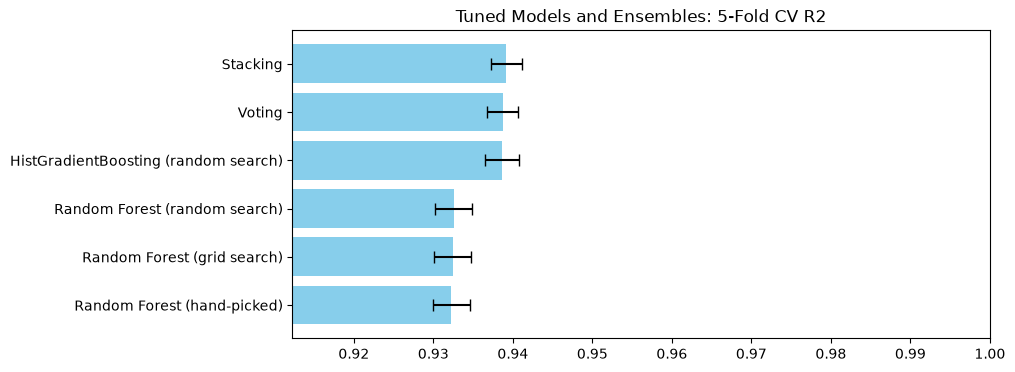

In [56]:
tuned_sorted = tuned.sort_values('CV R2 (mean)')
plt.figure(figsize=(9,4))
plt.barh(tuned_sorted['Model'], tuned_sorted['CV R2 (mean)'], xerr=tuned_sorted['CV R2 (std)'], color='skyblue', capsize=4)
plt.title('Tuned Models and Ensembles: 5-Fold CV R2')
lo = tuned_sorted['CV R2 (mean)'].min()
plt.xlim(lo - 0.02, 1)
plt.show()

### Using the team: teammates share one placement
All players in the same team get the same `winPlacePerc`, but the model predicts each player separately, so two teammates can get different predictions. A simple fix is to **average the predictions of each team** and give that average to every team member. We also clip the predictions to the range 0-1.

In [57]:
test_info = model_data.loc[X_test.index, ['matchId', 'groupId']]

for name in ['Voting', 'Stacking', 'HistGradientBoosting (random search)']:
    pred = np.clip(final_models[name][1].predict(X_test), 0, 1)
    team_pred = pd.Series(pred, index=X_test.index).groupby(test_info['groupId']).transform('mean').values
    print(f'{name:38s} | player R2: {r2_score(y_test, pred):.4f}  MAE: {mean_absolute_error(y_test, pred):.4f}'
          f'  ||  team-averaged R2: {r2_score(y_test, team_pred):.4f}  MAE: {mean_absolute_error(y_test, team_pred):.4f}')

Voting                                 | player R2: 0.9366  MAE: 0.0562  ||  team-averaged R2: 0.9565  MAE: 0.0483


Stacking                               | player R2: 0.9368  MAE: 0.0560  ||  team-averaged R2: 0.9567  MAE: 0.0482


HistGradientBoosting (random search)   | player R2: 0.9359  MAE: 0.0567  ||  team-averaged R2: 0.9559  MAE: 0.0488


In [58]:
# players in the same team with exactly the same stats show how much of the result is outside the player's control:
# a whole team gets one placement, even if one member did nothing
team = model_data.loc[X_test.index]
team_spread = team.groupby('groupId').agg(size=('kills', 'size'), kill_min=('kills', 'min'), kill_max=('kills', 'max'),
                                          walk_min=('walkDistance', 'min'), walk_max=('walkDistance', 'max'))
big = team_spread[team_spread['size'] >= 2]
print('teams with 2+ players in test set                 :', len(big))
print('...where one member walked less than 1/3 of another:', ((big['walk_min'] < big['walk_max'] / 3)).sum())

teams with 2+ players in test set                 : 3259
...where one member walked less than 1/3 of another: 788


**Tuning result: tuning Random Forest did not help, but boosting, combining models and averaging per team did.**

**What the grid search showed (`n_estimators` x `max_depth`):**
- **`max_depth` matters, `n_estimators` does not.** Depth 6 is too simple (CV R² 0.899), depth 10 gives 0.925, and from **depth 15 the score levels off at about 0.930-0.931**: depth 20, 30 and unlimited are all the same.
- Going from 100 to 300 trees changes the score by only about 0.0005, so more trees only make training slower.
- The best settings (depth 30, 300 trees, CV R² 0.9306) are almost the same as the hand-picked Random Forest, so the search **confirms our original choice**.

**What the randomized searches found:**
- **Random Forest** (20 combinations, also trying `min_samples_leaf` and `max_features`): best was depth 15, 70% of features, `min_samples_leaf` 3, 154 trees, CV R² **0.9308**. **No better than the grid search.**
- **HistGradientBoosting** (30 combinations): best was 573 trees of depth 8 with a slow learning rate (0.025), CV R² **0.9377**, better than Random Forest (0.931) on the same folds.

**Ensembles beyond bagging:**
- **Stacking** gave most weight to **HistGradientBoosting (0.71)** and Extra Trees (0.35), a small negative weight to Random Forest (-0.08, it adds nothing that Extra Trees doesn't already give) and almost nothing to KNN (0.03).
- **Voting** (plain average of tuned Random Forest, HistGradientBoosting and Gradient Boosting) scored test R² 0.9366 and MAE 0.0562.

**Final comparison:**
- The three Random Forests are all at **0.932-0.933** CV R², so tuning Random Forest changed nothing.
- **HistGradientBoosting (0.9387), Voting (0.9387) and Stacking (0.9392)** are about **0.006 higher**, about 3 times the variation between folds (std 0.002), so this is a **real but small** improvement.
- Stacking, Voting and HistGradientBoosting are **tied**: the differences (0.0005) are much smaller than the std. On the test set, Stacking and Voting are also almost identical (R² 0.9368 vs 0.9366, 83.4% within 0.1 for both).

**The biggest improvement came from using the team:** all players in a team get the same placement, so **averaging the predictions of each team** raised the test R² of the Voting model from **0.937 to 0.957** and lowered the MAE from **0.056 to 0.048**. That is a much bigger gain than all the tuning together. It works because teammates who did very different things still share one result: in **788 of 3,259 test teams** one member walked less than a third of the distance of another (for example, a player killed early whose team went on to win).

**Decision:** use the **Voting model with team-averaged predictions**. It ties for the best CV score with Stacking and HistGradientBoosting, and it is simpler than stacking (a plain average, no meta-model). Averaging three different models also makes it less dependent on one model's mistakes than HistGradientBoosting alone.

Test R2   : 0.9565
Test MAE  : 0.0483
Test RMSE : 0.064


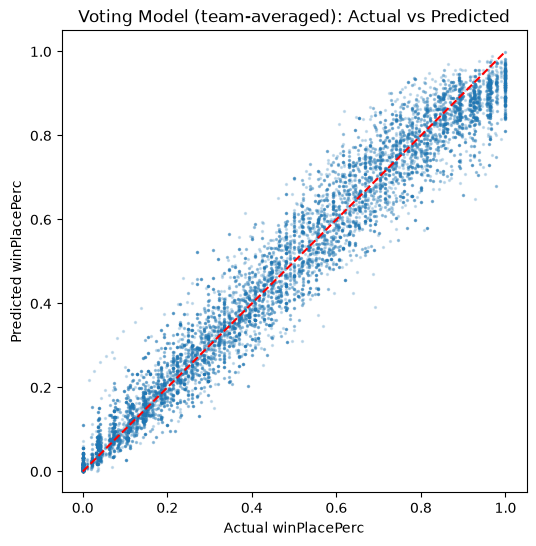

In [59]:
from sklearn.inspection import permutation_importance

BEST_NAME = 'Voting'   # set after looking at the comparison table above
best = final_models[BEST_NAME][1]
pred = np.clip(best.predict(X_test), 0, 1)
pred = pd.Series(pred, index=X_test.index).groupby(test_info['groupId']).transform('mean').values   # team average

print('Test R2   :', round(r2_score(y_test, pred), 4))
print('Test MAE  :', round(mean_absolute_error(y_test, pred), 4))
print('Test RMSE :', round(np.sqrt(mean_squared_error(y_test, pred)), 4))

plt.figure(figsize=(6,6))
plt.scatter(y_test, pred, s=2, alpha=0.2)
plt.plot([0, 1], [0, 1], color='red', linestyle='--')
plt.title(BEST_NAME + ' Model (team-averaged): Actual vs Predicted')
plt.xlabel('Actual winPlacePerc')
plt.ylabel('Predicted winPlacePerc')
plt.show()

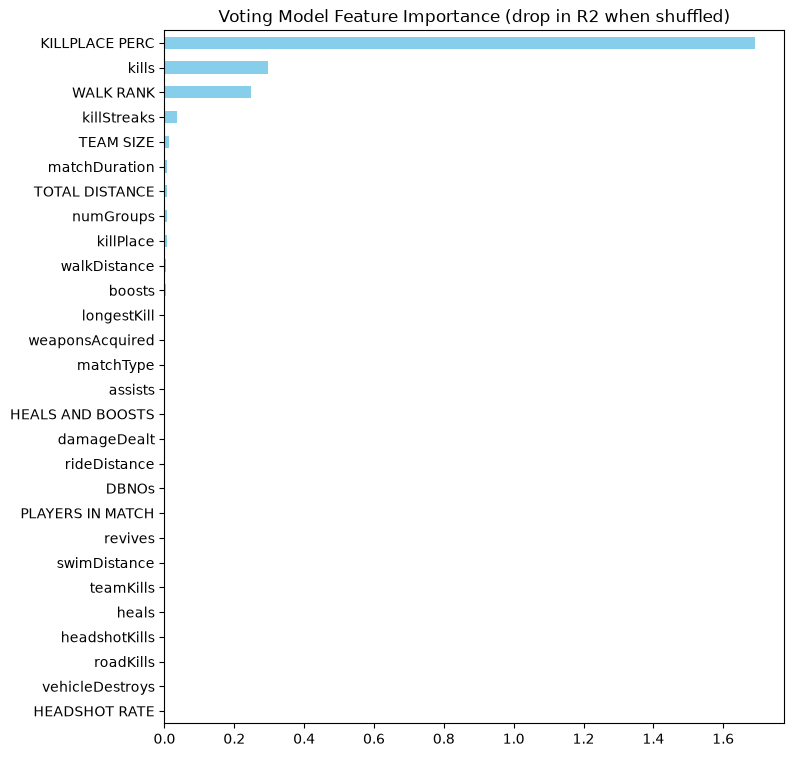

In [60]:
# permutation importance: shuffle one column at a time and see how much the test R2 drops
perm = permutation_importance(best, X_test, y_test, scoring='r2', n_repeats=3, random_state=42, n_jobs=-1)
importance = pd.Series(perm.importances_mean, index=X.columns).sort_values()
importance.plot(kind='barh', color='skyblue', figsize=(8,9))
plt.title(BEST_NAME + ' Model Feature Importance (drop in R2 when shuffled)')
plt.show()

In [61]:
# how close are the predictions to the real placement?
for gap in [0.05, 0.1, 0.2]:
    print(f'Predictions within {gap} of the real placement: {within(y_test, pred, gap):.1f}%')

# error by match type
err = pd.DataFrame({'match type': pd.Series(le.inverse_transform(X_test['matchType'])).str.replace('-fpp', '').values,
                    'actual': y_test.values, 'predicted': pred})
err['abs error'] = (err['predicted'] - err['actual']).abs()
print(err.groupby('match type')['abs error'].agg(['count', 'mean', 'median']).round(4))

# can the model find the winners? predicted top-10% vs real top-10%
real_top = err['actual'] >= 0.9
pred_top = err['predicted'] >= 0.9
print('\nreal top-10% players found by the model:', round((real_top & pred_top).sum() / real_top.sum() * 100, 1), '%')
print('players predicted top-10% who really were:', round((real_top & pred_top).sum() / pred_top.sum() * 100, 1), '%')

Predictions within 0.05 of the real placement: 61.9%
Predictions within 0.1 of the real placement: 88.4%
Predictions within 0.2 of the real placement: 99.5%
            count    mean  median
match type                       
duo          3432  0.0410  0.0317
solo         1368  0.0465  0.0321
squad        6485  0.0526  0.0422

real top-10% players found by the model: 48.0 %
players predicted top-10% who really were: 77.9 %


In [62]:
# some example predictions for players the model has never seen
show = model_data.loc[X_test.index, ['kills', 'walkDistance', 'boosts', 'heals', 'weaponsAcquired', 'killPlace']].copy()
show['MATCH TYPE'] = err['match type'].values
show['ACTUAL'] = y_test.values
show['PREDICTED'] = pred.round(4)
show.sample(10, random_state=3)

,kills,walkDistance,boosts,heals,weaponsAcquired,killPlace,MATCH TYPE,ACTUAL,PREDICTED
47453,1,456.50,0,0,2,35,solo,0.5217,0.4112
11557,0,1083.00,1,0,3,59,solo,0.4894,0.5604
48381,1,2675.00,2,1,5,27,duo,0.9388,0.8872
40575,0,27.43,0,0,1,90,duo,0.0816,0.0827
416,1,1548.00,3,4,4,29,squad,0.6667,0.7440
17943,1,57.80,0,0,1,46,solo,0.1250,0.1789
38034,2,899.90,8,3,3,14,squad,0.8276,0.6737
9904,3,2393.00,3,3,5,9,duo,1.0000,0.9151
38638,1,1102.00,0,2,4,32,duo,0.4130,0.4495
25862,6,4270.00,5,5,6,1,duo,1.0000,0.9336


**Result:** the **Voting model with team-averaged predictions** is the best model, with a test **R² of 0.957**: it explains about 96% of the variation in placement for players in matches it has never seen. Its average error (MAE) is **0.048**, which means it is off by about **5 places out of 100** on average (RMSE 0.064). **62% of predictions are within 0.05** of the real placement, **88% within 0.1** and **99.5% within 0.2**. It is accurate in every mode: the mean error is **0.041 in duo, 0.047 in solo and 0.053 in squad** (squad is hardest because a team of 4 has more mixed stats).

**Finding the top players:** of the players predicted to finish in the **top 10%**, **78% really did**, and the model found **48% of all real top-10% players**. Picking out the exact top players is harder than predicting the general placement, because the last minutes of a match (who wins the final fight) are not in the stats. The example predictions show how close it gets, e.g. a duo player with 6 kills and 4.3 km walked was predicted 0.93 and really won (1.0).

It is better than the best single model from the first comparison (Random Forest, test R² 0.931, CV 0.932). Tuning improved the CV R² only a little (0.932 to 0.939), but team averaging raised the test R² from 0.937 to 0.957.

**Feature importance:** by far the most important feature is **`KILLPLACE PERC`**, followed by **`kills`** and **`WALK RANK`**, then `killStreaks`. `killPlace` ranks the players by kills, and players with the same number of kills seem to be ordered by how long they survived, so **`killPlace` together with `kills` tells the model a lot about survival time**. `WALK RANK` adds how much the player moved compared with the rest of the match. Most other features show almost no importance here, but this is because they share their information with these top features (shuffling one of them does not hurt when another column carries the same information), not because they are useless: boosts, weapons and damage were all strongly correlated with placement in Part 1.

**Value for players and the game:** the model can predict a player's final placement from their stats within about 5 places out of 100. It can be used to **show players what a winning game looks like**, spot players whose placement doesn't fit their stats (possible cheaters or bugs) and help game designers check how much kills, looting and movement matter for winning.

# Part 3: Suggestions for Players

## How can players finish higher and win more matches?

In [63]:
# winners vs everyone else, inside the same match type (median values)
df['RESULT'] = pd.cut(df['winPlacePerc'], bins=[-0.01, 0.5, 0.9, 0.999, 1], labels=['bottom half', 'top 50-10%', 'top 10%', 'winner'])
df.pivot_table(index='RESULT', columns='MATCH TYPE', values=['walkDistance', 'boosts', 'heals', 'kills', 'weaponsAcquired', 'damageDealt'],
               aggfunc='median').round(1)

boosts            damageDealt               heals             \
MATCH TYPE     duo solo squad         duo   solo  squad   duo solo squad   
RESULT                                                                     
bottom half    0.0  0.0   0.0        43.0   23.3   50.5   0.0  0.0   0.0   
top 50-10%     1.0  1.0   2.0       113.3  100.0  113.7   1.0  1.0   1.0   
top 10%        3.0  4.0   3.0       247.7  252.0  208.7   2.0  2.0   2.0   
winner         4.0  5.0   3.0       435.2  548.2  305.3   3.0  2.0   2.0   

            kills            walkDistance                 weaponsAcquired  \
MATCH TYPE    duo solo squad          duo    solo   squad             duo   
RESULT                                                                      
bottom half   0.0  0.0   0.0        171.6   110.1   227.4             2.0   
top 50-10%    1.0  1.0   1.0       1699.0  1399.0  2061.0             5.0   
top 10%       2.0  2.0   1.0       2759.0  2501.0  2859.0             5.0   
winner        4.0  5.0   3.0       2983.0  2672.0  3060.0             5.0   

                        
MATCH TYPE  solo squad  
RESULT                  
bottom half  2.0   2.0  
top 50-10%   5.0   5.0  
top 10%      5.0   5.0  
winner       6.0   5.0

In [64]:
# chance of a top-10% finish (winPlacePerc >= 0.9) by walking rank inside the match
df['TOP 10'] = (df['winPlacePerc'] >= 0.9).astype(int)
df['WALK RANK GROUP'] = pd.cut(df['WALK RANK'], bins=[0, 0.25, 0.5, 0.75, 0.9, 1], labels=['bottom 25%', '25-50%', '50-75%', '75-90%', 'top 10%'])
(df.pivot_table(index='WALK RANK GROUP', columns='MATCH TYPE', values='TOP 10', aggfunc='mean') * 100).round(1)

MATCH TYPE,duo,solo,squad
WALK RANK GROUP,,,
bottom 25%,0.2,0.0,0.6
25-50%,0.4,0.5,1.0
50-75%,4.6,5.1,5.8
75-90%,23.8,23.6,24.2
top 10%,52.9,53.2,49.4


In [65]:
# boosts: top-10% chance by number of boosts, in each match type
df['BOOST GROUP'] = pd.cut(df['boosts'], bins=[-1, 0, 1, 2, 4, 6, 40], labels=['0', '1', '2', '3-4', '5-6', '7+'])
(df.pivot_table(index='BOOST GROUP', columns='MATCH TYPE', values='TOP 10', aggfunc='mean') * 100).round(1)

MATCH TYPE,duo,solo,squad
BOOST GROUP,,,
0,1.3,1.4,2.0
1,6.4,6.6,7.8
2,14.7,14.6,15.7
3-4,32.0,32.2,30.4
5-6,56.1,57.5,47.9
7+,77.4,80.3,63.8


In [66]:
# fair comparison: among players who walked about the same distance (same walk group and match type),
# does using more boosts still go with a higher placement?
fair = df[df['WALK GROUP'].isin(['1-2km', '2-3km', '3-5km'])]
fair.pivot_table(index=['MATCH TYPE', 'WALK GROUP'], columns='BOOST GROUP', values='winPlacePerc', aggfunc='median', observed=True).round(3)

BOOST GROUP                0      1      2    3-4    5-6     7+
MATCH TYPE WALK GROUP                                          
duo        1-2km       0.609  0.660  0.694  0.750  0.830  0.917
           2-3km       0.756  0.792  0.826  0.870  0.915  0.957
           3-5km       0.808  0.848  0.875  0.915  0.954  0.977
solo       1-2km       0.660  0.705  0.739  0.794  0.878  0.947
           2-3km       0.776  0.814  0.842  0.878  0.919  0.959
           3-5km       0.817  0.850  0.876  0.907  0.939  0.976
squad      1-2km       0.522  0.577  0.615  0.667  0.760  0.852
           2-3km       0.704  0.750  0.786  0.828  0.885  0.926
           3-5km       0.786  0.840  0.867  0.900  0.929  0.962

In [67]:
# vehicles: compared within the same match type and the same walking distance group
df.pivot_table(index=['MATCH TYPE', 'USED VEHICLE'], columns='WALK GROUP', values='winPlacePerc', aggfunc='median', observed=True).round(3)

WALK GROUP               0-100m  100-500m  500m-1km  1-2km  2-3km  3-5km  \
MATCH TYPE USED VEHICLE                                                    
duo        no             0.083     0.283     0.468  0.660  0.844  0.915   
           yes            0.146     0.348     0.522  0.688  0.844  0.898   
solo       no             0.104     0.354     0.546  0.720  0.864  0.915   
           yes            0.186     0.413     0.574  0.739  0.865  0.907   
squad      no             0.064     0.214     0.370  0.577  0.793  0.900   
           yes            0.107     0.258     0.433  0.600  0.800  0.885   

WALK GROUP                5km+  
MATCH TYPE USED VEHICLE         
duo        no            0.935  
           yes           0.896  
solo       no            0.938  
           yes           0.904  
squad      no            0.923  
           yes           0.885

In [68]:
# kills: top-10% chance by kills, in each match type
df['KILL GROUP'] = pd.cut(df['kills'], bins=[-1, 0, 1, 2, 4, 7, 100], labels=['0', '1', '2', '3-4', '5-7', '8+'])
(df.pivot_table(index='KILL GROUP', columns='MATCH TYPE', values='TOP 10', aggfunc='mean') * 100).round(1)

MATCH TYPE,duo,solo,squad
KILL GROUP,,,
0,3.4,2.8,4.4
1,9.9,8.6,10.6
2,15.9,18.1,17.6
3-4,31.4,34.6,28.3
5-7,55.5,62.3,47.8
8+,79.4,86.6,69.2


In [69]:
# kills vs survival: among players who walked about the same distance, do more kills still help?
fair = df[df['WALK GROUP'].isin(['1-2km', '2-3km', '3-5km'])]
fair.pivot_table(index=['MATCH TYPE', 'WALK GROUP'], columns='KILL GROUP', values='winPlacePerc', aggfunc='median', observed=True).round(3)

KILL GROUP                 0      1      2    3-4    5-7     8+
MATCH TYPE WALK GROUP                                          
duo        1-2km       0.638  0.681  0.694  0.733  0.787  0.870
           2-3km       0.791  0.833  0.851  0.891  0.933  0.978
           3-5km       0.848  0.891  0.911  0.938  0.959  1.000
solo       1-2km       0.685  0.722  0.753  0.796  0.865  0.955
           2-3km       0.804  0.843  0.874  0.905  0.947  0.989
           3-5km       0.840  0.879  0.907  0.938  0.969  0.990
squad      1-2km       0.556  0.600  0.625  0.654  0.700  0.769
           2-3km       0.741  0.793  0.821  0.852  0.897  0.960
           3-5km       0.821  0.885  0.903  0.929  0.963  1.000

In [70]:
# team play in duo and squad: revives and assists (top-10% chance)
team_modes = df[df['MATCH TYPE'] != 'solo']
print((team_modes.pivot_table(index=pd.cut(team_modes['revives'], [-1, 0, 1, 2, 50], labels=['0', '1', '2', '3+']),
                              columns='MATCH TYPE', values='TOP 10', aggfunc='mean') * 100).round(1), '\n')
print((team_modes.pivot_table(index=pd.cut(team_modes['assists'], [-1, 0, 1, 2, 50], labels=['0', '1', '2', '3+']),
                              columns='MATCH TYPE', values='TOP 10', aggfunc='mean') * 100).round(1))

MATCH TYPE   duo  squad
revives                
0            8.1    8.1
1           23.3   20.9
2           34.6   28.4
3+          37.9   34.9 



MATCH TYPE   duo  squad
assists                
0            6.7    6.4
1           23.1   20.5
2           43.4   37.3
3+          67.0   57.8


In [71]:
# what did the winners (winPlacePerc = 1) do in each match type?
df[df['winPlacePerc'] == 1].groupby('matchType')[['kills', 'walkDistance', 'boosts', 'heals', 'weaponsAcquired']].median().round(1)

,kills,walkDistance,boosts,heals,weaponsAcquired
matchType,,,,,
duo,4.0,2757.5,5.0,3.0,6.0
duo-fpp,4.0,3049.0,4.0,3.0,5.0
solo,4.0,2070.0,4.0,1.0,6.0
solo-fpp,6.0,2847.5,6.0,2.0,6.0
squad,3.0,2893.0,4.0,2.0,5.0
squad-fpp,3.0,3116.0,3.0,2.0,5.0


## Suggestions for Players

**A note on fair comparison:** players who survive longer have more time to walk, loot, heal and fight, so almost every stat "goes with" a better placement. To be fair, the suggestions below compare players **within the same match type** (solo / duo / squad), and where possible **among players who walked about the same distance** (1-2 km, 2-3 km, 3-5 km), so that survival time is roughly the same. This data cannot prove cause and effect, but these comparisons show which habits still matter when survival time is equal.

### 1. Keep moving and stay ahead of the zone
| Walking rank in the match | Top-10% chance (duo) | (solo) | (squad) |
|---|---|---|---|
| bottom 25% | 0.2% | 0.0% | 0.6% |
| 50-75% | 4.6% | 5.1% | 5.8% |
| 75-90% | 23.8% | 23.6% | 24.2% |
| **top 10%** | **52.9%** | **53.2%** | **49.4%** |

* **Half of the players who walked the most in their match finished in the top 10%.** Winners walked a median of **2.7-3.1 km**, compared with 110-230 m for the bottom half.
* Part of this is because survivors have more time to walk, but the message is still clear: **don't camp in one spot**. Move with the safe zone and avoid hot drop zones where many players die in the first minutes.

---

### 2. Use your boosts
| Squad players who walked 2-3 km | 0 boosts | 1 | 2 | 3-4 | 5-6 | 7+ |
|---|---|---|---|---|---|---|
| Median placement | 0.704 | 0.750 | 0.786 | 0.828 | 0.885 | **0.926** |

* **Even among players who walked the same distance, more boosts means a higher placement**, in every mode and every walking group (e.g. solo 1-2 km: 0.660 with 0 boosts vs 0.947 with 7+).
* The top-10% chance goes from **1.3-2.0% with 0 boosts to 64-80% with 7 or more**. Boosts give health over time and faster movement, so pick up energy drinks and painkillers and use them before fights and zone moves.

---

### 3. Fight, but pick your fights (especially in solo)
| Top-10% chance by kills | 0 | 1 | 2 | 3-4 | 5-7 | 8+ |
|---|---|---|---|---|---|---|
| Solo | 2.8% | 8.6% | 18.1% | 34.6% | 62.3% | **86.6%** |
| Duo | 3.4% | 9.9% | 15.9% | 31.4% | 55.5% | 79.4% |
| Squad | 4.4% | 10.6% | 17.6% | 28.3% | 47.8% | 69.2% |

* Kills still matter among players who walked the same distance: solo players who walked 2-3 km have a median of **0.804 with 0 kills vs 0.989 with 8+ kills**.
* **Kills matter most in solo and least in squad.** In squad (1-2 km walked) the median only goes from 0.556 to 0.769, and squad winners have a median of only **3 kills** vs **4-6 in solo**. In squad, staying alive together matters more than individual kills.

---

### 4. Use vehicles to move early, but don't rely on them late
| Median placement (squad) | walked 0-100 m | 500 m-1 km | 2-3 km | 3-5 km | 5 km+ |
|---|---|---|---|---|---|
| No vehicle | 0.064 | 0.370 | 0.793 | **0.900** | **0.923** |
| Used vehicle | **0.107** | **0.433** | 0.800 | 0.885 | 0.885 |

* The overall chart (0.729 vs 0.340) makes vehicles look much better than they are. **On the same walking distance, a vehicle helps players who walk little** (it gets them to the safe zone), but among long survivors (3 km+) players **without a vehicle place slightly higher** in every mode. Vehicles are loud and easy to spot, so use them to move across the map early and leave them before the final zones.

---

### 5. Play as a team (duo and squad)
* Players who **revived at least one teammate** had a top-10% chance of **23% (duo) / 21% (squad)**, compared with **8% for players with no revives**.
* **Assists** show the same pattern: 0 assists gives a 6-7% top-10% chance, 2 assists 37-43%, 3+ assists **58-67%**. Teams that fight together and pick each other up go further.

---

### 6. Don't over-loot
* Winners picked up a median of **5-6 weapons**, the same as players who finished in the top 50-10% (5). The median placement rises up to about 5 weapons (0.70) and then hardly improves (9+: 0.80).
* Winners used a median of only **2-3 heals**, and placement stops improving after about 3 heals. **Loot what you need (a main weapon, some boosts and heals) and spend the rest of the time moving and positioning.**

---

### 7. Use the model to review your game
* After a match, compare your stats with the model's predicted placement. **88% of predictions are within 0.1** of the real result. If you placed much lower than predicted, look at the end of your game (positioning, the final fights) rather than your loot or kills.

### Summary
To finish higher and win more matches, players should **keep moving with the safe zone**, **use boosts regularly**, **take fights they can win (most important in solo)**, **use vehicles to move early but not in the final zones**, **revive and support teammates in duo and squad**, and **not waste time over-looting**. In squad, team survival matters more than individual kills.

# Model Comparison Report

**Goal:** Predict a PUBG player's **final placement `winPlacePerc`** (0 = last, 1 = winner) from their in-game stats. The full data has 4,411,341 players after cleaning. The models were trained on a random sample of **600 whole matches (56,168 players)**, split **by match**: 80% of matches for training (44,883 players) and 20% for testing (11,285 players).

| Model | Train R² | Test R² | MAE | RMSE | % within 0.1 |
|---|---|---|---|---|---|
| **Random Forest** | 0.983 | **0.931** | **0.058** | **0.081** | **82.4%** |
| Gradient Boosting | 0.924 | 0.921 | 0.062 | 0.087 | 80.3% |
| Decision Tree | 0.946 | 0.909 | 0.066 | 0.093 | 77.9% |
| KNN | 0.911 | 0.893 | 0.073 | 0.100 | 73.8% |
| Linear Regression | 0.869 | 0.867 | 0.081 | 0.112 | 70.6% |

*R² = how much of the variation in placement the model explains (1.0 is perfect). MAE = average error (0.05 = about 5 places out of 100). RMSE = like MAE but punishes big mistakes more. % within 0.1 = share of players predicted within 0.1 of their real placement.*

**5-fold cross-validation by match (more reliable than one split)**

| Model | CV R² (mean) | CV R² (std) | CV MAE |
|---|---|---|---|
| **Gradient Boosting (tuned)** | **0.936** | 0.002 | **0.056** |
| Random Forest | 0.932 | 0.002 | 0.057 |
| Gradient Boosting | 0.921 | 0.002 | 0.061 |
| Decision Tree | 0.910 | 0.002 | 0.065 |
| KNN | 0.889 | 0.003 | 0.073 |
| Linear Regression | 0.869 | 0.005 | 0.081 |

**Hyperparameter Tuning & Advanced Ensembles**

| Model | How it was built | Test R² | Test MAE | % within 0.1 | CV R² (mean) |
|---|---|---|---|---|---|
| Stacking | RF + HGB + Extra Trees + KNN, Ridge meta-model | **0.9368** | **0.0561** | **83.4%** | **0.9392** |
| **Voting** | average of tuned RF + HGB + GB | 0.9366 | 0.0562 | **83.4%** | 0.9387 |
| HistGradientBoosting (random search) | 30 random combinations | 0.9358 | 0.0568 | 83.1% | 0.9387 |
| Random Forest (random search) | 20 random combinations | 0.9316 | 0.0576 | 82.8% | 0.9326 |
| Random Forest (grid search) | `n_estimators` x `max_depth`, 18 combinations | 0.9312 | 0.0580 | 82.6% | 0.9324 |
| Random Forest (hand-picked) | 200 trees, unlimited depth, min_samples_leaf 3 | 0.9311 | 0.0580 | 82.4% | 0.9323 |
| **Voting + team average** | average the predictions of each team | **0.9565** | **0.0483** | **88.4%** | - |

The grid search showed that Random Forest needs trees of depth 15 or more (depth 6: 0.899, depth 15+: about 0.930) and that more than 100 trees adds almost nothing. Tuning Random Forest did not improve it, but **boosting and the ensembles improved CV R² by about 0.006** (3 times the std). **Averaging the predictions per team gave the biggest gain of all (+0.02 R²).**

**How each model performed**
- **Linear Regression (R² 0.87):** the weakest, but much better than usual, because the strongest features (`WALK RANK`, `killPlace`) have an almost straight-line relationship with placement. It can't capture combinations (e.g. kills matter more in solo than in squad).
- **KNN (R² 0.89):** better, but it treats every feature as equally important when measuring "closeness", so less useful columns confuse it.
- **Decision Tree (R² 0.91):** captures combinations, but a single tree is unstable and its predictions jump in steps.
- **Gradient Boosting (default, R² 0.92):** 100 shallow trees are a bit too simple. **Tuned (400 trees, depth 6) it reaches 0.936 CV**, the best of the first models.
- **Random Forest (R² 0.931, CV 0.932):** the best of the first five on the test set. Its train R² (0.98) is higher than its test R² (0.93), but the grid search showed that limiting the depth does not help.
- **HistGradientBoosting (CV 0.939):** the best single tuned model, and the one the stacking model trusted most.
- **Voting (CV 0.939, test 0.937; 0.957 with team averaging):** ties with Stacking and HistGradientBoosting, and becomes clearly the best once the team average is added.

**Recommended Model for Production: Voting Regressor with team-averaged predictions** (average of tuned Random Forest, HistGradientBoosting and Gradient Boosting, then the same prediction for every member of a team)

The Voting model is chosen because:
1. With team averaging it has a **test R² of 0.957** and an **MAE of 0.048** (about 5 places out of 100).
2. **88% of its predictions are within 0.1** of the real placement and 99.5% within 0.2.
3. It ties for the **best cross-validated R² (0.939)**, about 0.006 above the best Random Forest, which is more than the normal variation between folds.
4. It is **simpler than stacking**, which scored the same: it only averages three predictions, with no meta-model to train. Averaging three different models also makes it less dependent on one model's mistakes.
5. Team averaging matches how the game works (**one placement per team**) and costs nothing extra to run.

# Report on Challenges Faced

| # | Challenge in the data | Technique used | Reason |
|---|---|---|---|
| 1 | **Very large file:** 4.4 million rows, 660 MB (1.2 GB in memory). | Used the full data for the analysis, and a **random sample of 600 whole matches** (56,168 players) for the models. | Training 5 models, cross-validation and hyperparameter searches on 4.4 million rows would take many hours. 56,000 players is still plenty to learn the patterns, and the CV std (0.002) shows the results are stable. |
| 2 | **Missing value:** 1 row had no `winPlacePerc`. | Dropped the row. | It is a match with only 1 player, so a placement cannot exist. It is only 1 row out of 4.4 million. |
| 3 | **Custom / event match types:** 10 of the 16 `matchType` values (`normal`, `crash`, `flare`), 35,267 rows. | Removed them and kept the 6 ranked modes. | They have different rules (e.g. no weapons in crash mode, or custom games), so they would confuse the model. They are only 0.8% of the data. |
| 4 | **Cheaters:** kills without moving (1,535), more than 30 kills, 10+ road kills, kills from 1 km+, 80+ weapons, 40+ heals. | Removed these **357** rows (after removing event modes). | These values are impossible or almost impossible for a fair player, and would teach the model wrong patterns. |
| 5 | **Unreliable columns:** `rankPoints` = -1 in 38% of rows; `killPoints` / `winPoints` = 0 in 60%. | Dropped all three. | Their "no value" codes are mixed with real values, and their correlation with placement is only 0.01. |
| 6 | **Same information twice:** `maxPlace` and `numGroups` (0.998). | Dropped `maxPlace`. | It adds nothing that `numGroups` doesn't already give. |
| 7 | **Stats depend on the match:** e.g. long matches have more walking for everyone, and matches have different numbers of players. | Created **`WALK RANK`** (rank inside the match) and **`KILLPLACE PERC`** (killPlace / players in the match). | `WALK RANK` has a higher correlation with placement (0.89) than `walkDistance` (0.81), because it compares a player with the others in the same match. |
| 8 | **Text category:** `matchType`. | `LabelEncoder`. | Models need numbers, and tree models handle label-encoded categories well. |
| 9 | **Zero-heavy, skewed features:** 57% of players have 0 kills, 75% 0 ride distance (skew up to 3.4). | Checked outliers with the IQR method and boxplots but **kept** them. | The IQR method marked every player who used a car as an outlier, so it does not fit this data. The extreme values are real good players, and tree models are not affected by extreme values. |
| 10 | **Teammates share one placement:** if teammates are split between train and test, the model can "remember" the team. | Split the data **by match** (`GroupShuffleSplit`), and used **`GroupKFold`** for all cross-validation, tuning and stacking folds. | Every match is either fully in training or fully in testing, so the test score is honest. 0 matches appear in both sets. |
| 11 | **`StackingRegressor` cannot use groups** for its own folds. | Gave it the `GroupKFold` splits directly (`cv=list(...)`), also inside cross-validation. | Otherwise its meta-model would learn from teammates' predictions and look better than it really is. |
| 12 | **Non-linear patterns:** e.g. kills matter more in solo than in squad. | Compared 5 algorithms; chose tree-based ensembles. | Linear Regression explained 87% of the variation; tree models reached 93-94% because they capture these combinations. |
| 13 | **Overfitting:** Random Forest had train R² 0.98 but test R² 0.93. | Used a test set and **5-fold cross-validation by match** to measure the real performance. | Testing on unseen matches shows the true performance. |
| 14 | **Hand-picked settings might not be the best.** | **GridSearchCV** (`n_estimators` x `max_depth`) and **RandomizedSearchCV** (Random Forest and HistGradientBoosting), using only the training data and 3-fold `GroupKFold`. | It showed that Random Forest was already at its best, and found better settings for boosting (CV 0.939). |
| 15 | **Choosing between close models:** Stacking, Voting and HistGradientBoosting were within 0.0005 R². | Compared them with 5-fold CV and the test set, looking at R², MAE and % within 0.1. | The differences were much smaller than the std, so we chose the simpler and more robust Voting model instead of chasing a tiny difference. |
| 16 | **Teammates get one placement, but the model predicts each player separately.** | **Averaged the predictions of each team**. | All teammates share one result, even when one was killed early. This raised the test R² from 0.937 to 0.957, more than all the tuning together. |
| 17 | **Very slow to run:** the whole notebook took about 2 hours. | Used `n_jobs` to run on all CPU cores and a sample of matches. | Each step (5 models, CV, three searches, two ensembles) has to train many models. |
| 18 | **Misleading group comparisons:** players who survive longer walk, loot, heal and drive more, so every stat looks good. | Compared players **within the same match type and the same walking distance** in Part 3. | Without this, vehicles look like they double the placement (0.73 vs 0.34); with a fair comparison they only help players who walk little. This makes sure the suggestions are based on real differences. |